# 3-servo: inductance

Measure the winding's inductance and the time constant of its current rise inside the assembled servo, from duty-step bursts into the held horn at three seats, and settle which window model the later stages carry.

## Purpose

The current in a winding does not follow the voltage at once. It rises with a time constant $\tau = L / R$ ("tau"), the inductance $L$ over the resistance $R$. That time constant sets how much the current ripples inside one PWM window, how fast a duty step turns into torque, and how fast a current loop can be closed. Stage 2 measured it on two bare motors of this family, mg90-b and mg90-c, with the rotor locked by a bar at twelve angles. Those two are the type here. This notebook reads the same quantities on mg90-d through its gear train, case and leads, so the stage 5 current loop is designed on numbers from a servo and not only from a bare motor.

The firmware reads the current once per PWM period, at the crest sample, one shunt conversion near the middle of the drive window. A window model is what turns that one sample into the period's mean current at any duty and rail. Stage 2's motor-model built one for the type, with a loss conductance $G$ ("G"), a conductance across the winding whose current the shunt sees inside the window and not between windows, and an inductance that changes with the current. Part of this notebook asks how much of that model the bursts can measure on mg90-d, and what is carried from the type.

The servo also holds its horn in more than one way. The horn lock, a pin through the horn into the case, holds it at mid travel, and a press can wind the train against the lock before the bursts. The low end stop holds it at the end of travel, through a stopper that flexes under load. The last question is whether the three seats give the same $L$, $\tau$ and burst $R$, and if not, which one the resistance notebook's stop laps should trust.

mg90-d is a new motor from a new servo of the same brand, installed in a new, never used MG90 body whose gears were cleaned and regreased by hand with Super Lube. Its motor is not torn down, so every number here is read through the servo's own leads and connector.

## Procedure

The servo is mg90-d on board dev-v006-2A-D, powered from the DPS-150 bench supply, with the board's adapter on its bus at 3 Mbps. The board runs the experiment image, so every drive is open loop. The sitting runner, `python -m oscnb.sitting servo`, ran `stages/3-servo/inductance/plan.py` in three sittings, on a 5 V rail. At each seat it runs stage 2's five groups of bursts with `osc-lab burst`, the shunt and both taps interleaved by the free-running ADC, each group one call into its own folder, in this order.

- `g1-fwd-25`, five bursts at 25 % forward, the first group after the seat was set.
- `g2-fwd-40`, five bursts at 40 % forward. A duty change with the sign kept.
- `g3-rev-40`, five bursts at 40 % reverse. A reversal with the duty kept.
- `g4-rev-25`, five bursts at 25 % reverse. A duty change with the sign kept.
- `g5-rev-25-rested`, three bursts at 25 % reverse after a 20 s rest. A rest alone, the same step as the group before it.

The three seats are three plans.

1. `locked`, sitting 4. The horn lock on at mid travel. Earlier in the same sitting the resistance plan's `locked` pass ran six 100 % laps of 300 ms into the same lock, three on 3.3 V and three on 3.7 V, both directions, and the last of them ended about 20 s before the first group.
2. `wound`, sitting 5. The lock on again on a freshly centered horn. A reverse press of 24 % for 300 ms, 1.2 V effective, winds the train against the lock 40 s before the first group, and the seat is read before the press, after it and after the groups.
3. `stop`, sitting 6. The horn free. The same reverse press, with osc-lab's park skipped, takes the horn to the low end stop and leaves the train wound into it. The groups run there, the seat is read before the first burst and after the last, and the horn is centered at the end.

Each burst is about half a millisecond of drive at under half an amp, and the bursts of a group come 150 ms apart, so the copper stays within a fraction of a degree of the case.

## Data

Everything is under `telemetry/mg90-d__dev-v006-2A-D/`.

- `inductance/locked-4/`, `inductance/wound-5/` and `inductance/stop-6/`, one per seat. Each holds `<group>/burst-<k>.csv`, one file per burst, and `<group>/meta.json`, the board's sense constants and the group's settings. In a burst file `k` is the sample index and `code` the raw ADC sample, and the meta fields repeat on the first row. `step_q15` is the step's duty and sign, `step_index` the sample at which the step was applied, `vbus_raw` the rail read before the arm, `pos` the pot. `marks.csv` holds the host time each group and rest began, and `seats.csv` the seat's pot readings. `wound-5/seat/` and `stop-6/seat/` hold the press.
- `resistance/locked-4/`, the six 100 % laps into the lock of sitting 4, `chains.csv` and one folder per lap. They give the resistance at 100 % this notebook takes off the window's own slope.
- `sittings/servo-4.csv`, `servo-5.csv` and `servo-6.csv`, the three sittings' manifests. Before every dataset the runner reads `pos`, `ntc_raw` and `vbus_raw` with torque off and logs them there.

One burst is set aside, by a rule stated here, before any seat is compared with another. A burst that reads a different current from the rest of its group from its first period on, at the same applied volts, has a different circuit under the brushes and not a different rise, so it does not measure the winding the other bursts measure. One burst meets it, the fifth burst of the stop's forward 25 % group, `stop-6/g1-fwd-25/burst-4.csv`. Its first window current is about a fifth over its group's. It stays in the per-burst fits, the group table of the first section and every figure, drawn marked, and it is left out of the seat medians, the window reads and the result file. The section on the first burst's extra volts reads it.

How the cells below read a burst's timing is stage 2's, unchanged. A frame is the shunt, tap A, the shunt, tap B, one conversion every 52 timer ticks or 1.083 us at 48 ticks per microsecond. A burst holds 960 samples and the step sits near the buffer's half, so the first half is the amplifier's zero and the second half, about ten PWM periods, is the rise. The decay is slow, so the drive window is centered on the crest and between windows the bridge shorts the winding through its two low-side switches.

The libraries, then the pair and its folders.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

from oscnb import boards, bursts as bu, figures, motors, results, scales
from oscnb import servos, tel
from oscnb.display import show
from oscnb.figures import BLUE, GREEN, INK, MUTED, ORANGE, RED

In [2]:
SERVO = servos.SERVOS["mg90-d"]         # the servo: pot, train, rated V
MOTOR = motors.MOTORS[SERVO.motor]      # its motor, with its counted parts
BOARD_KEY = boards.DEFAULT              # the board, checked on every group
PAIR = f"{SERVO.key}__{BOARD_KEY}"      # the pair, the result file's name
PAIR_DIR = (Path("../../../telemetry") / PAIR).resolve()
RUNS = PAIR_DIR / "inductance"          # the three seats' datasets
SEATS = {"lock": RUNS / "locked-4",     # the horn lock at mid travel
         "wound": RUNS / "wound-5",     # the lock after a reverse press
         "stop": RUNS / "stop-6"}       # the low end stop after a press
SITTING = {"lock": 4, "wound": 5, "stop": 6}     # each seat's sitting
ANCHOR_DIR = PAIR_DIR / "resistance" / "locked-4"   # the 100 % laps
MANIFESTS = PAIR_DIR / "sittings"       # one manifest per sitting
print(SERVO.key, "on", BOARD_KEY, "from",
      ", ".join(str(results.rel(p)) for p in SEATS.values()))
print("the 100 % laps from", results.rel(ANCHOR_DIR))

mg90-d on dev-v006-2A-D from telemetry/mg90-d__dev-v006-2A-D/inductance/locked-4, telemetry/mg90-d__dev-v006-2A-D/inductance/wound-5, telemetry/mg90-d__dev-v006-2A-D/inductance/stop-6
the 100 % laps from telemetry/mg90-d__dev-v006-2A-D/resistance/locked-4


Every group names its board in its own `meta.json`. The board is looked up from that sense block, never assumed, and its check raises if any constant disagrees with the registry.

In [3]:
def board_of(folder):
    # the board a group's meta.json names, its sense block checked, and
    # the meta itself
    meta = json.loads((folder / "meta.json").read_text())
    board = boards.from_meta(meta)      # identified from the data itself
    where = str(results.rel(folder))
    if board is None:
        raise ValueError(f"{where}: no board matches {meta['sense']}")
    board.check_meta(meta, where)       # raises on any mismatch
    return board, meta


BOARD, _ = board_of(SEATS["lock"] / "g1-fwd-25")
if BOARD.key != BOARD_KEY:              # the data names another board
    raise ValueError(f"the data names {BOARD.key}, not {BOARD_KEY}")
print("board", BOARD.key, "from the first group's sense block")

board dev-v006-2A-D from the first group's sense block


### Stage 1 values carried in

The current goes through the current-scale result, the terminal and rail volts through the terminal-chain result, and the bridge's edges, the window's scale and the crest sample's place through sample-timing, all graded on this board in stage 1. Bridge-states ran the same burst method on fixed inductors, and its ratio of the window's inductance to the period fit's is the method's own gap.

In [4]:
SCALES = scales.load(BOARD)             # stage 1's current and volt lines
LAGS = SCALES.edge_lags()               # slow decay's edges, two rails
TIMING = SCALES.sample_timing           # sample-timing's result file
WINDOW_SCALE = TIMING["window_scale"]   # window V_on / i over 100 % V / I
K, K_LO, K_HI = (WINDOW_SCALE[b] for b in ("value", "lo", "hi"))
# ticks from the crest at which the firmware's shunt sample closes
CREST_AT = int(TIMING["crest_sample_ticks"]["shunt"]["value"])
BSR = SCALES.bridge_states              # the same method on inductors
ARR = BOARD.pwm_arr                     # ticks from the trough to the crest
PERIOD = 2 * ARR                        # ticks per PWM period
PERIOD_US = PERIOD / bu.TICKS_PER_US    # us per PWM period
T_S = PERIOD_US * 1e-6                  # the same period in s, for the fit
SCALES.describe()
print(f"window scale k {K:.4f} ({K_LO:.4f} to {K_HI:.4f}), crest shunt "
      f"sample {CREST_AT:+d} ticks from the crest, period {PERIOD_US:.0f} us")

current: counts over the zero = +5.3 + 1135.0 x amps (1133.8 to 1136.3), graded over 0.23 to 1.31 A
terminals: tap difference = +2.4 + 248.37 x volts (248.20 to 248.53)
rail: tap = +6.0 + 247.54 x volts at rest
bridge ON edge 40 ticks after the commanded start, shunt crossing 44, OFF edge 14 after the commanded end, shunt settled 72 after the start
fast decay: ON edge 8 ticks after the commanded start, OFF edge 12 after the end
window scale k 1.0063 (1.0046 to 1.0081), crest shunt sample +31 ticks from the crest, period 50 us


### Stage 2 type values carried in

mg90-b is the type motor of this family and mg90-c the second motor. Their inductance results are the grade. Their rest-resistance results give the resistance at 100 % and the smallest inertia, motor-model gives the type's window model and bemf-coast its back-EMF constant $K_e$ ("K e") and the reading term with a meter in the loop. Every one of them is a comparison or a bound here, never a constant mg90-d's own results are computed with.

In [5]:
TYPE_KEY = SERVO.type_motor             # mg90-b, the type motor
TYPE_B = results.read("2-motor", "inductance", pair=TYPE_KEY)
TYPE_C = results.read("2-motor", "inductance", pair="mg90-c")
RR_B = results.read("2-motor", "rest-resistance", pair=TYPE_KEY)
RR_C = results.read("2-motor", "rest-resistance", pair="mg90-c")
MM_B = results.read("2-motor", "motor-model", pair=TYPE_KEY)
BEMF_B = results.read("2-motor", "bemf-coast", pair=TYPE_KEY)
KE_TYPE = BEMF_B["ke_v_s_per_rad"]["value"]   # V s/rad, comparison only
J_LO_TYPE = RR_B["j_runup_kg_m2"]["lo"]       # kg m^2, smallest run-up
R_TERM_B = RR_B["r_term_median_ohm"]["value"]   # ohm, 100 %, locked
R_TERM_C = RR_C["r_term_median_ohm"]["value"]
G_READ = BEMF_B["reading_term_a_per_v"]["value"]   # A per V, the meter's
print(f"{TYPE_KEY}: L {TYPE_B['l_mh']['value']:.3f} mH, tau "
      f"{TYPE_B['tau_us']['value']:.0f} us, burst R "
      f"{TYPE_B['r_burst_ohm']['value']:.3f} ohm, R at 100 % "
      f"{R_TERM_B:.3f} ohm, Ke {KE_TYPE * 1e3:.4f} mV s/rad")
print(f"mg90-c: L {TYPE_C['l_mh']['value']:.3f} mH, tau "
      f"{TYPE_C['tau_us']['value']:.0f} us, burst R "
      f"{TYPE_C['r_burst_ohm']['value']:.3f} ohm, R at 100 % "
      f"{R_TERM_C:.3f} ohm")

mg90-b: L 0.833 mH, tau 194 us, burst R 4.308 ohm, R at 100 % 4.455 ohm, Ke 1.1684 mV s/rad
mg90-c: L 0.841 mH, tau 199 us, burst R 4.218 ohm, R at 100 % 4.402 ohm


### Stage 3 values carried in

The sag notebook ran a 300 ms stop lap of 1.5 V effective into the low stop at each of thirteen rails, 18 to 25 % duty, the rotor held. Its finding is quoted here from its result file, never re-read from its data. The laps read $V_\mathrm{eff} / I_\mathrm{crest}$, the effective volts over the crest current, at 4.344 ohm, flat with the rail at -0.0055 +/- 0.0071 ohm per volt.

In [6]:
SAG = results.read("3-servo", "sag", pair=PAIR)   # the sag finding
I_LAP = SAG["lap_current_a"]["value"]       # A, the laps' mean current
R_LAP = SAG["r_stop_lap_ohm"]["value"]      # ohm, V_eff / I_crest
SLOPE_Q = SAG["r_stop_lap_per_v_ohm"]       # ohm per V of rail, se bounds
SLOPE = SLOPE_Q["value"]
SLOPE_SE = (SLOPE_Q["hi"] - SLOPE_Q["lo"]) / 2
print(f"sag stop laps: {R_LAP:.3f} ohm at {I_LAP:.3f} A, on the rail "
      f"{SLOPE:+.4f} +/- {SLOPE_SE:.4f} ohm/V")

sag stop laps: 4.344 ohm at 0.330 A, on the rail -0.0055 +/- 0.0071 ohm/V


The groups, their labels, and the constants of the method, each with its unit and reason. The method's choices are stage 2 inductance's.

In [7]:
GROUPS = ["g1-fwd-25", "g2-fwd-40", "g3-rev-40", "g4-rev-25",
          "g5-rev-25-rested"]           # capture order at every seat
# the change before each group's first burst, as the figures label it
CHANGE = {"g1-fwd-25": "seat set\n+ reversal",
          "g2-fwd-40": "duty\n25 to 40 %",
          "g3-rev-40": "reversal",
          "g4-rev-25": "duty\n40 to 25 %",
          "g5-rev-25-rested": "20 s rest"}
# the same changes as result-file keys
CHANGE_KEY = {"g1-fwd-25": "g1_seat_set_and_reversal",
              "g2-fwd-40": "g2_duty_25_to_40", "g3-rev-40": "g3_reversal",
              "g4-rev-25": "g4_duty_40_to_25",
              "g5-rev-25-rested": "g5_rest_20s"}
DUTIES = (25, 40)                       # %, the two steps
COLOR = {25: BLUE, 40: ORANGE}          # one color per duty
SEAT_COLOR = {"lock": BLUE, "wound": GREEN, "stop": ORANGE}
DUTY_MARK = {25: "o", 40: "s"}          # one marker per duty
QTY = {"l_mh": "L", "tau_us": "tau", "r_ohm": "R",
       "l_ripple_mh": "ripple L"}       # the four quantities read
SIGN = {1: "fwd", -1: "rev"}
# the burst set aside by the rule in the Data section: seat, group, burst
SET_ASIDE = ("stop", "g1-fwd-25", 4)

In [8]:
EARLY_PAIRS = 3       # period pairs in the short fit, the first 150 us
END_PERIODS = 3       # periods read at each end of a burst
SHARE_PAIRS = 4       # pairs 1 to 4, where a first burst's excess sits
ZONE = (-30, 100)     # ticks around each commanded edge, the edge zone
BIN = 4               # ticks, the edge profile's bin
TRAVEL_STEPS = 4000   # time steps of the free rotor's double integral
STALL_FROM_S = 0.060  # s, rest-resistance's stall line starts here
ANCHOR_V = 3.7        # V, the 100 % laps' rail on stage 1's graded lines
PRE_GUARD = 8         # samples before the step kept out of the rest read
BOOT_DRAWS = 4000     # resamples of a seat's median
SEED = 0              # the bootstrap's seed, so a re-run repeats it

### The bursts

Every burst of the three seats, one row each, with what its meta says.

In [9]:
def burst_rows(seat):
    # every burst of one seat, one row each, groups in capture order
    rows = []
    for group in GROUPS:
        folder = SEATS[seat] / group
        _, meta_g = board_of(folder)        # checked on every group
        for k, df in enumerate(bu.load(folder)):
            m = bu.meta(df)                 # the meta on the first row
            rows.append({"seat": seat, "group": group, "k": k,
                         "first": k == 0, "pct": bu.duty_pct(m),
                         "sign": 1 if m["step_q15"] > 0 else -1,
                         "samples": len(df), "step_index": m["step_index"],
                         "frame_len": m["frame_len"],
                         # the rail before the arm, stage 1's rest line
                         "rail_v": float(SCALES.rail_v(m["vbus_raw"])),
                         "rail_mv_meta": meta_g["rail_mv"],
                         "pos": m["pos"], "seated": m["seated"],
                         # the amplifier's zero over the pre-step half
                         "zero_counts": bu.zero(df, ARR), "df": df})
    return pd.DataFrame(rows)


B = pd.concat([burst_rows(s) for s in SEATS], ignore_index=True)
B["set_aside"] = ((B["seat"] == SET_ASIDE[0])
                  & (B["group"] == SET_ASIDE[1])
                  & (B["k"] == SET_ASIDE[2]))

In [10]:
for seat, g in B.groupby("seat", sort=False):
    size = g.groupby("group").size()    # bursts per group
    print(f"{seat}: {len(g)} bursts in {len(size)} groups ({size.min()} "
          f"to {size.max()} each), {g['samples'].min()} to "
          f"{g['samples'].max()} samples, step at {g['step_index'].min()} "
          f"to {g['step_index'].max()}, frame {g['frame_len'].unique()}, "
          f"rail {g['rail_v'].min():.2f} to {g['rail_v'].max():.2f} V "
          f"before the arm, zero {g['zero_counts'].min():.0f} to "
          f"{g['zero_counts'].max():.0f} counts")
print(f"set aside: {B['set_aside'].sum()} burst, "
      f"{'/'.join(map(str, SET_ASIDE))}")

lock: 23 bursts in 5 groups (3 to 5 each), 960 to 960 samples, step at 484 to 484, frame [4], rail 4.98 to 4.99 V before the arm, zero 1212 to 1214 counts
wound: 23 bursts in 5 groups (3 to 5 each), 960 to 960 samples, step at 484 to 484, frame [4], rail 4.97 to 5.00 V before the arm, zero 1213 to 1215 counts
stop: 23 bursts in 5 groups (3 to 5 each), 960 to 960 samples, step at 484 to 484, frame [4], rail 4.98 to 5.00 V before the arm, zero 1213 to 1215 counts
set aside: 1 burst, stop/g1-fwd-25/4


Each seat holds 23 bursts in five groups, every burst 960 samples with its step at sample 484, and the rail read 4.97 to 5.00 V before every arm. The amplifier's zero sits at 1212 to 1215 counts across the three sittings.

### marks.csv, seats.csv and the manifests

`marks.csv` holds the host time each group and the rest began and the end of the run. `seats.csv` holds the seat's pot reading each time the plan read it, `pos`, with `shift_counts` its move from the seat's first reading. The manifest's probes are parsed by a helper local to this notebook.

In [11]:
def marks(seat):
    # the host time each group and the rest began, and the run's end
    return pd.read_csv(SEATS[seat] / "marks.csv")


def seats_table(seat):
    # the seat's pot readings as the plan read them
    return pd.read_csv(SEATS[seat] / "seats.csv")


def manifest_probes(sitting):
    # the pos, ntc and vbus probes of one sitting's manifest, in order
    m = pd.read_csv(MANIFESTS / f"servo-{sitting}.csv")
    p = m[m["event"] == "probe"].copy()
    parts = p["detail"].str.extract(
        r"^(.*): pos (-?\d+), ntc_raw (\d+), vbus_raw (\d+)")
    p["where"] = parts[0]               # the dataset or the moment
    p["pos"] = parts[1].astype(int)
    p["ntc_raw"] = parts[2].astype(int)
    p["vbus_raw"] = parts[3].astype(int)
    return p[["t_host", "where", "pos", "ntc_raw", "vbus_raw"]]


show(marks("lock"), n=None)
for seat in SEATS:
    show(seats_table(seat).assign(seat_dir=seat), n=None)

,t_host,mark
0,14:00:58.029,g1-fwd-25
1,14:01:04.467,g2-fwd-40
2,14:01:07.033,g3-rev-40
3,14:01:09.619,g4-rev-25
4,14:01:12.240,rest
5,14:01:32.246,g5-rev-25-rested
6,14:01:33.934,done


,t_host,seat,pos,shift_counts,seat_dir
0,14:00:58.029,lock,2016,1,lock
1,14:01:34.220,lock,2016,1,lock


,t_host,seat,pos,shift_counts,seat_dir
0,14:11:38.385,lock,2017,0,wound
1,14:12:18.365,lock,2022,5,wound
2,14:12:52.525,lock,2026,9,wound


,t_host,seat,pos,shift_counts,seat_dir
0,14:43:04.038,low stop,3,0,stop
1,14:43:38.109,low stop,3,0,stop


### The order of the groups

Every group and the rest of each seat on one time axis, from the host times in `marks.csv`, one row per seat. Each bar runs from the mark of its group to the next mark, so it holds the group's bursts and the host's time around them. Filled bars are forward, hatched bars reverse, blue 25 % and orange 40 %, gray the rest. The black diamonds are the seat's readings in `seats.csv`, and the one before zero on the wound row is the reading before the press. The cross marks the group that holds the burst set aside.

In [12]:
def order_bars(ax, seat, row):
    # one seat's groups and rest as bars from each mark to the next
    mk = marks(seat)
    t0 = mk["t_host"].iloc[0]                   # the first group's mark
    spans = zip(mk.iloc[:-1].iterrows(), mk["t_host"].iloc[1:])
    for (_, r), t_end in spans:
        x, w = r["t_host"] - t0, t_end - r["t_host"]
        if r["mark"] == "rest":
            ax.barh(row, w, left=x, height=0.6, color=MUTED, alpha=0.3)
            continue
        g = B[(B["seat"] == seat) & (B["group"] == r["mark"])]
        c, forward = COLOR[g["pct"].iloc[0]], g["sign"].iloc[0] > 0
        ax.barh(row, w, left=x, height=0.6, edgecolor=c, lw=0.8,
                color=c if forward else "white",
                hatch=None if forward else "////")
        if g["set_aside"].any():                # the burst set aside
            ax.plot(x + w / 2, row, "x", color=INK, ms=10, mew=2)
        ax.annotate(r["mark"][:2], (x + w / 2, row - 0.38), ha="center",
                    va="bottom", fontsize=8)
    st = seats_table(seat)                      # the seat's readings
    ax.plot(st["t_host"] - t0, [row] * len(st), "D", color=INK, ms=5)

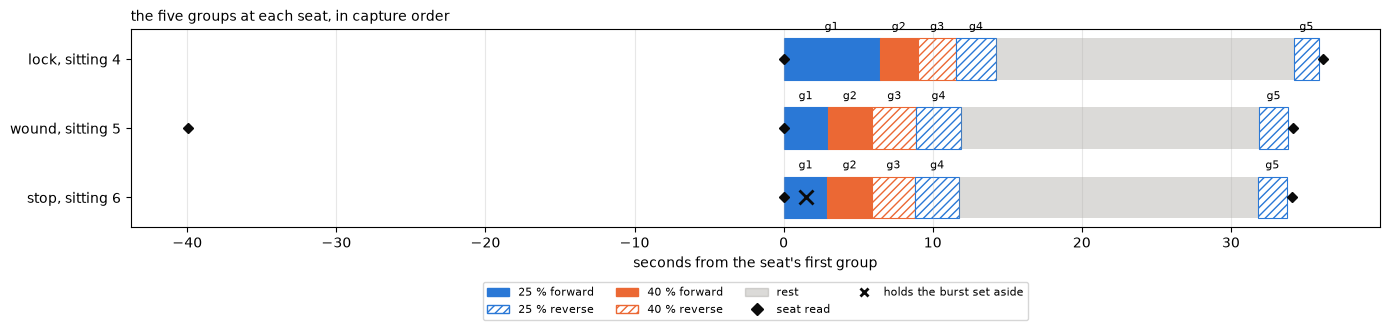

In [13]:
legend = [Patch(color=BLUE, label="25 % forward"),
          Patch(facecolor="white", edgecolor=BLUE, hatch="////",
                label="25 % reverse"),
          Patch(color=ORANGE, label="40 % forward"),
          Patch(facecolor="white", edgecolor=ORANGE, hatch="////",
                label="40 % reverse"),
          Patch(color=MUTED, alpha=0.3, label="rest"),
          plt.Line2D([], [], ls="none", marker="D", color=INK,
                     label="seat read"),
          plt.Line2D([], [], ls="none", marker="x", color=INK, mew=2,
                     label="holds the burst set aside")]
fig, ax = plt.subplots(figsize=(14, 3.6))
for row, seat in enumerate(SEATS):
    order_bars(ax, seat, row)
ax.set_yticks(range(len(SEATS)),
              [f"{s}, sitting {SITTING[s]}" for s in SEATS])
ax.invert_yaxis()
ax.grid(alpha=figures.GRID_ALPHA, axis="x")
figures.label(ax, x="seconds from the seat's first group", grid=False)
ax.set_title("the five groups at each seat, in capture order",
             loc="left", fontsize=10)
ax.legend(handles=legend, fontsize=8, loc="upper center", ncol=4,
          bbox_to_anchor=(0.5, -0.25))
figures.finish(fig)

In [14]:
for seat in SEATS:
    mk = marks(seat)
    gaps = mk["t_host"].diff().iloc[1:]         # s from mark to mark
    st = seats_table(seat)
    lead = mk["t_host"].iloc[0] - st["t_host"].iloc[0]   # seat to g1
    print(f"{seat}: marks " + ", ".join(
        f"{a}->{b} {g:.2f} s" for a, b, g in
        zip(mk["mark"].iloc[:-1], mk["mark"].iloc[1:], gaps))
        + f"; the first seat read {lead:.0f} s before g1")
laps = pd.read_csv(ANCHOR_DIR / "chains.csv")
after = marks("lock")["t_host"].iloc[0] - laps["t_end"].iloc[-1]
print(f"the last 100 % lap of sitting 4 ended {after:.0f} s before the "
      "lock's g1")

lock: marks g1-fwd-25->g2-fwd-40 6.44 s, g2-fwd-40->g3-rev-40 2.57 s, g3-rev-40->g4-rev-25 2.59 s, g4-rev-25->rest 2.62 s, rest->g5-rev-25-rested 20.01 s, g5-rev-25-rested->done 1.69 s; the first seat read 0 s before g1
wound: marks g1-fwd-25->g2-fwd-40 2.95 s, g2-fwd-40->g3-rev-40 2.99 s, g3-rev-40->g4-rev-25 2.97 s, g4-rev-25->rest 2.96 s, rest->g5-rev-25-rested 20.01 s, g5-rev-25-rested->done 1.97 s; the first seat read 40 s before g1
stop: marks g1-fwd-25->g2-fwd-40 2.94 s, g2-fwd-40->g3-rev-40 2.97 s, g3-rev-40->g4-rev-25 2.90 s, g4-rev-25->rest 2.97 s, rest->g5-rev-25-rested 20.01 s, g5-rev-25-rested->done 1.97 s; the first seat read 0 s before g1
the last 100 % lap of sitting 4 ended 20 s before the lock's g1


Every seat ran the same sequence. The groups came 2.6 to 3.0 s apart when no rest separated them, 6.4 s from g1 to g2 at the lock, so a group's first burst followed the last burst of the group before it by about 2 s or more. At the lock the seat was read as the first group began, and the last resistance lap ended 20 s earlier. Each lap runs both directions, so g1 there also follows a reverse drive. At the wound lock the reverse press came 40 s before g1, and at the stop the reverse press set the seat just before g1.

### One burst at each seat

The second burst of the forward 25 % group at each seat as recorded, the shunt and the two taps against time from the step. The second rather than the first, since the first burst of a group can read apart from the others, which a later section shows.

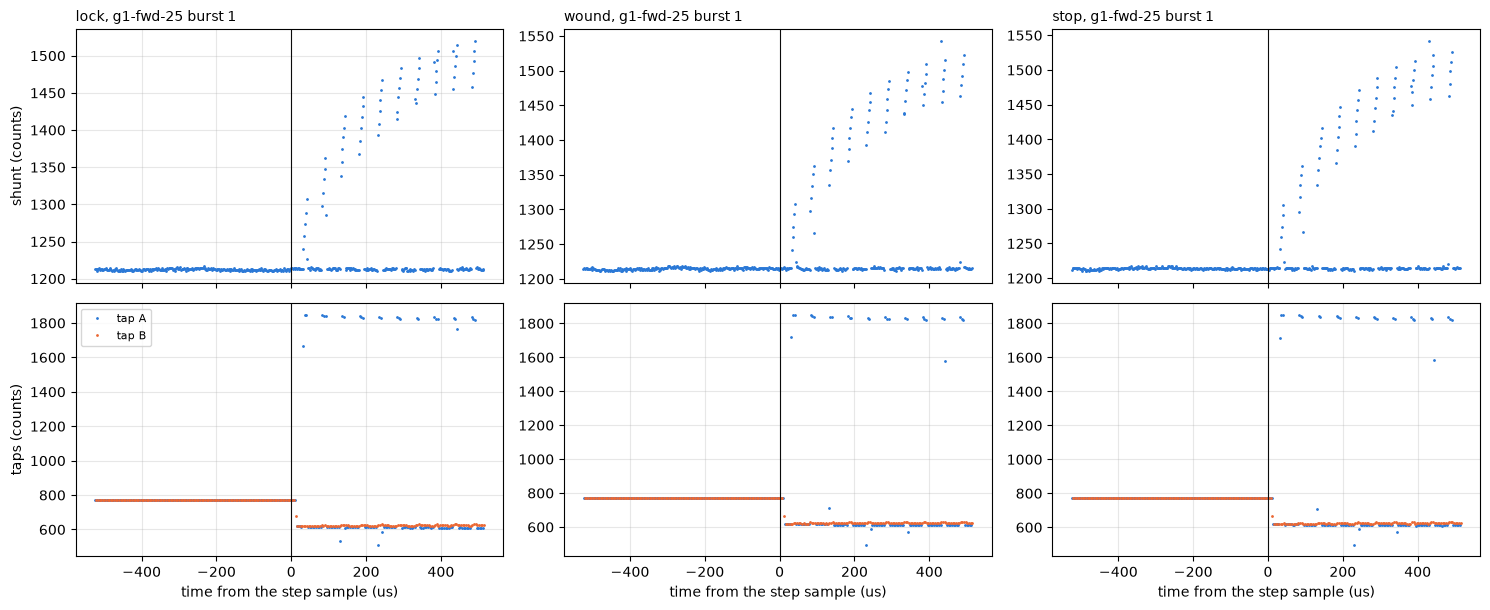

In [15]:
def one(seat, group, k=1):
    # the k-th burst of one group at one seat, the second by default
    at = (B["seat"] == seat) & (B["group"] == group) & (B["k"] == k)
    return B[at].iloc[0]


fig, ax = plt.subplots(2, 3, figsize=(15, 6.2), sharex=True)
for col, seat in enumerate(SEATS):
    e = one(seat, "g1-fwd-25")
    meta, _, shunt, tap_a, tap_b = bu.phase(e["df"], ARR)   # streams
    us = bu.STEP_TICKS / bu.TICKS_PER_US        # us per sample
    t_us = (np.arange(len(e["df"])) - meta["step_index"]) * us
    code_ = e["df"]["code"].to_numpy(float)
    ax[0, col].plot(t_us[shunt], code_[shunt], ".", ms=2, color=BLUE)
    ax[1, col].plot(t_us[tap_a], code_[tap_a], ".", ms=2, color=BLUE,
                    label="tap A")
    ax[1, col].plot(t_us[tap_b], code_[tap_b], ".", ms=2, color=ORANGE,
                    label="tap B")
    for axis in ax[:, col]:
        axis.axvline(0, color=INK, lw=0.8)      # the step sample
    ax[0, col].set_title(f"{seat}, g1-fwd-25 burst 1", loc="left",
                         fontsize=10)
    figures.label(ax[1, col], x="time from the step sample (us)")
figures.label(ax[0, 0], y="shunt (counts)")
figures.label(ax[1, 0], y="taps (counts)")
ax[1, 0].legend(fontsize=8, loc="upper left")
figures.finish(fig)

The three seats look alike at this scale, the amplifier's zero for half a millisecond and then a window every 50 us whose level climbs as the current builds. Before the step both taps read the bias node. After it tap A is the driven terminal, near the rail inside each window, and tap B the return, held at ground with tap A between windows.

### The same bursts folded onto the period

Every sample after the step at its phase in the PWM period, colored from the first full period to the last, the shunt over the burst's own zero in milliamps on top and the terminal difference in volts below, one column per seat. The commanded window is shaded, the dotted lines are the bridge's edges sample-timing found on a resistor, and the dashed orange line is the instant the firmware's crest shunt sample closes.

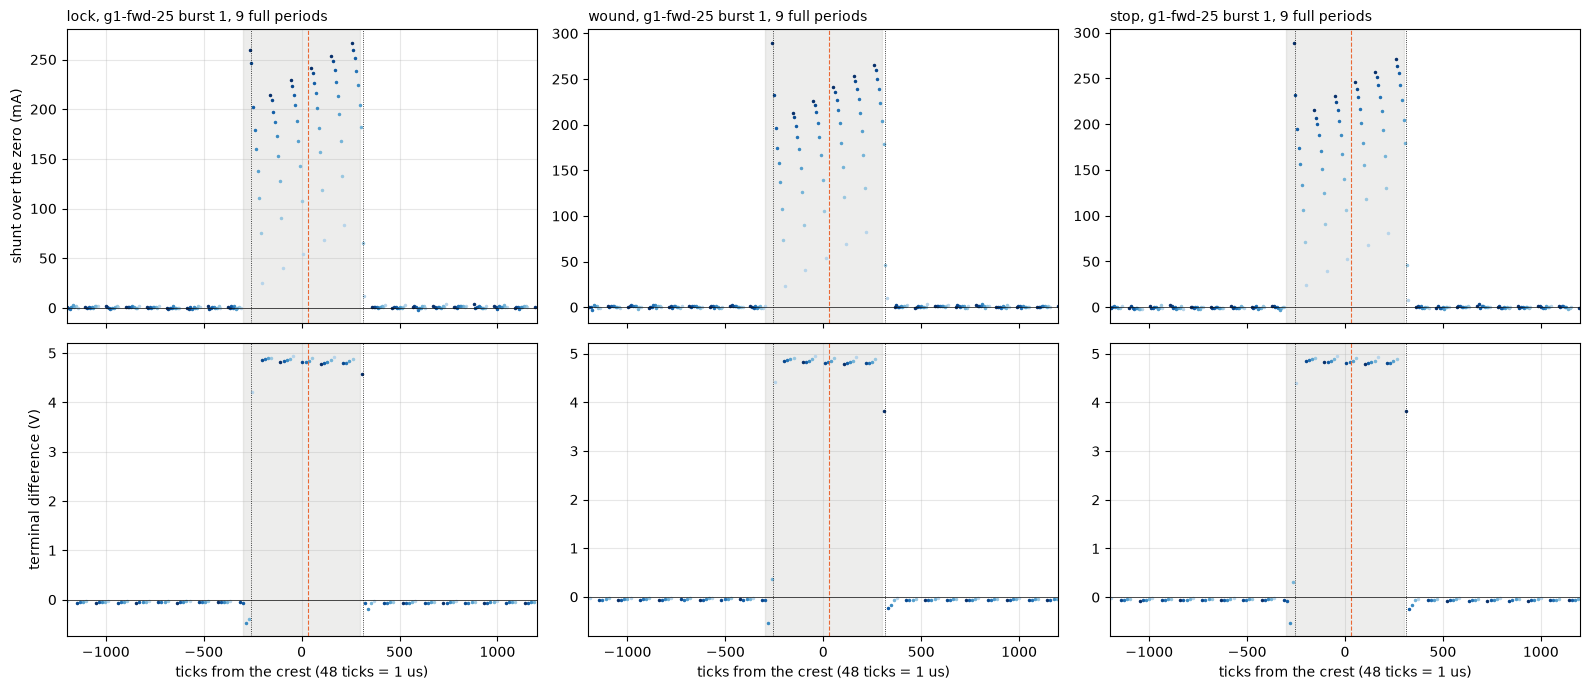

In [16]:
fig, ax = plt.subplots(2, 3, figsize=(16, 7), sharex=True)
for col, seat in enumerate(SEATS):
    e = one(seat, "g1-fwd-25")
    s, _, half = bu.samples(e["df"], BOARD, "crest")    # folded samples
    zero = bu.zero(e["df"], ARR)
    post = s[(s["n"] >= 0) & s["full"]]          # full periods after
    n_per = post["n"].max() + 1
    shade = figures.shades("Blues", n_per, lo=0.3, hi=1.0)
    for n, g in post.groupby("n"):
        sh = g[g["stream"] == "sh"]
        ma = (sh["code"] - zero) / SCALES.counts_per_a * 1e3
        ax[0, col].plot(sh["tc"], ma, ".", ms=3, color=shade[n])
        # tap B interpolated to tap A's samples, 52 ticks apart
        a, b = g[g["stream"] == "ta"], g[g["stream"] == "tb"]
        vb = np.interp(a["tick"], b["tick"], b["code"])
        volts = SCALES.volts(e["sign"] * (a["code"] - vb),
                             SCALES.terminal_offset_counts)
        ax[1, col].plot(a["tc"], volts, ".", ms=3, color=shade[n])
    for axis in ax[:, col]:
        axis.axvspan(-half, half, color=MUTED, alpha=0.15)
        axis.axvline(-half + LAGS["on"], color=INK, lw=0.6, ls=":")
        axis.axvline(half + LAGS["off"], color=INK, lw=0.6, ls=":")
        axis.axvline(CREST_AT, color=ORANGE, lw=0.8, ls="--")
        axis.axhline(0, color=INK, lw=0.5)
        axis.set_xlim(-ARR, ARR)
    ax[0, col].set_title(f"{seat}, g1-fwd-25 burst 1, {n_per} full "
                         "periods", loc="left", fontsize=10)
    figures.label(ax[1, col], x="ticks from the crest (48 ticks = 1 us)")
figures.label(ax[0, 0], y="shunt over the zero (mA)")
figures.label(ax[1, 0], y="terminal difference (V)")
figures.finish(fig)

The fold reads as stage 2's did on the bare motor, at all three seats. The shunt jumps at the ON edge to a level that climbs from period to period, ramps up through the window, and falls back to its zero at the OFF edge. Between windows it stays at the zero, so the current circulating through the low side in the brake interval does not cross it. The terminal difference is near the rail inside the window and a few tens of millivolts under zero outside it. The crest sample closes just past the middle of the window.

## Method

Every estimator here is stage 2 inductance's, unchanged, run on mg90-d's bursts. The two new reads are the resistance at 100 % from the resistance sitting's locked laps, and the crest instant's place inside the window.

### The window level is the winding current

Between windows the shunt reads its zero, so the shunt's mean over a period is the window's share of the winding current, and not the current. Inside the window the whole winding current crosses the shunt. Each period's current $i_n$ is read as a line through the window's settled shunt samples, evaluated at the middle between the bridge's two edges. For a ripple of two straight segments that is the current's mean over the period. The line is read over the burst's own zero, the shunt before the step, which already holds current-scale's in-drive offset, so nothing more comes off it.

### The applied volts

The volts each period applies, $V_n$, are the tap difference over the whole period, read in two parts weighted by their durations, the window's settled tap samples and the brake interval's samples clear of both edges, through the terminal-chain result. $V_n$ falls through the burst as the bridge and the supply carry more current, so the fit takes the volts each period actually applied.

### The fit

The winding is a resistance and an inductance in series. The rotor is held, so no back-EMF (electromotive force, the voltage a turning rotor generates) enters,

$$v = R\,i + L\,\frac{di}{dt}.$$

Over one period of length $T$, from the middle of window $n$ to the middle of window $n+1$,

$$L\,(i_{n+1} - i_n) = T\left(V_n - R\,\frac{i_n + i_{n+1}}{2}\right),$$

linear in $R$ and $L$, so one least squares over a burst's eight period pairs gives both, and $\tau = L / R$. A one-pole winding gives the same $R$ and $L$ from any stretch of the burst, so the same fit also runs over the first 3 pairs and every length up to 8, and $R$ and $L$ against the number of pairs is the test of one pole. Stage 2 found the type is not one pole on this time scale.

In [17]:
def fit(table, pairs=None):
    # R and L by least squares over the first `pairs` period pairs, all of
    # them by default, each divided by the window's scale, with the
    # per-pair residual
    i, v = table["i_a"].to_numpy(), table["v_v"].to_numpy()
    p = len(i) - 1 if pairs is None else pairs
    di = i[1:p + 1] - i[:p]                  # the change over each pair
    im = (i[1:p + 1] + i[:p]) / 2            # the pair's mean current
    X = np.c_[im, di / T_S]                  # V_n = R i_mean + L di / T
    (r, l), *_ = np.linalg.lstsq(X, v[:p], rcond=None)
    resid = v[:p] - X @ np.array([r, l])     # volts the fit leaves
    return {"r_ohm": r / K, "l_mh": l / K * 1e3, "tau_us": l / r * 1e6,
            "pairs": p,
            "resid_rms_mv": float(np.sqrt(np.mean(resid ** 2)) * 1e3),
            "resid_mv": resid * 1e3}


def run(table, f):
    # the current the fit predicts, stepped forward from the first
    # period's measurement through each period's measured volts
    r = f["r_ohm"] * K                       # back on the window's scale
    l = f["l_mh"] * K * 1e-3
    i = [table["i_a"].iloc[0]]
    for v in table["v_v"].iloc[:-1]:
        i.append((v + i[-1] * (l / T_S - r / 2)) / (l / T_S + r / 2))
    return np.array(i)

### The ripple

The slope of the line inside each window is the current's rise while the window applies $V_\mathrm{on}$ ("V on"), the terminal volts with the bridge on, so the window on its own gives a second inductance,

$$L_\mathrm{ripple} = \frac{V_\mathrm{on} - R\,i_n}{(di/dt)_\mathrm{window}},$$

read over the 12 to 20 us of one window where the fit reads 50 us periods. $R$ here is the winding's resistance at 100 %, the anchor below, since the burst's own $R$ moves with the fit's length. $L_\mathrm{ripple}$ ("L ripple") is the median of the last three periods, and of the first three for its start. The fit with $R$ pinned at the same anchor gives a third $L$.

In [18]:
def ripple_l(table, r_ohm):
    # the window's own L per period in mH, (V_on - R i) over the window's
    # slope, R on the window's scale and the result divided by k
    v_on, i = table["v_on_v"].to_numpy(), table["i_a"].to_numpy()
    slope = table["slope_a_per_s"].to_numpy()
    return (v_on - r_ohm * K * i) / slope / K * 1e3


def pinned_l(table, r_ohm):
    # L in mH with R pinned, over every pair: V_n - R i_mean = L di / T
    i, v = table["i_a"].to_numpy(), table["v_v"].to_numpy()
    x = np.diff(i) / T_S
    y = v[:-1] - r_ohm * K * (i[1:] + i[:-1]) / 2
    return (x @ y) / (x @ x) / K * 1e3

### The window's scale

$R$ and $L$ are volts over amps read inside a short window, and stage 1 graded the chains at 100 % duty, where nothing switches. Sample-timing read the window's $V_\mathrm{on} / i$ on bursts into the bare resistor over the same resistor's 100 % rungs in one capture and wiring, and its result is the window's scale $k$, 1.0063 (1.0046 to 1.0081). $R$, $L$ and $L_\mathrm{ripple}$ are divided by it, and it cancels in $\tau$ and in every ratio.

### The 100 % anchor

No rest-resistance result exists for mg90-d yet, so the resistance at 100 % comes from the resistance sitting's locked laps, read the way rest-resistance reads a lap. At 100 % nothing switches, so the crest sample is the mean and no window model enters. For each lap, $V/I$ row by row from 60 ms to the lap's end gives a line, and its value at the drive's first row is the lap's $R$, before the copper warms. Only the 3.7 V laps are used. The 3.3 V laps sit off stage 1's graded lines, with current-scale 8 % and terminal-chain 13 % off there. The anchor is this notebook's reading of the resistance sitting's laps, and the resistance notebook is where it gets confirmed.

In [19]:
def locked_lap_r():
    # rest-resistance's read of a 100 % lap, V/I at the drive's first row
    # by a line through V/I from 60 ms to the lap's end, per lap and
    # direction, on the resistance sitting's locked laps
    chains = pd.read_csv(ANCHOR_DIR / "chains.csv")
    rows = []
    for _, c in chains.iterrows():
        df, meta = tel.load(ANCHOR_DIR / c["folder"], BOARD)
        zero_i, _ = tel.rest_zeros(df)      # the lap's torque-off zero
        for seg, g in df[df["seg"] > 0].groupby("seg"):
            g = tel.drive_rows(g)           # the driven rows only
            d = int(g["dir"].iloc[0])       # the lap's direction
            i = SCALES.amps(g["current_raw"].to_numpy(float), zero_i)
            taps = (g["vmotor_a"] - g["vmotor_b"]).to_numpy(float) * d
            u = SCALES.volts(taps, SCALES.terminal_offset_counts)
            t = np.arange(len(g)) / BOARD.tick_hz     # s from the start
            late = t >= STALL_FROM_S
            line = np.polyfit(t[late], (u / i)[late], 1)
            rows.append({"chain": int(c["k"]), "volts_set": c["volts_set"],
                         "dir": d, "r_first_ohm": line[1],
                         "r_slope_ohm_per_s": line[0],
                         "i_a": float(np.median(i[late])),
                         "v_v": float(np.median(u[late])),
                         "pos_before": c["pos_before"],
                         "pos_after": c["pos_after"]})
    return pd.DataFrame(rows)


AN = locked_lap_r()
GRADED = AN[AN["volts_set"] == ANCHOR_V]     # the 3.7 V laps
R_ANCHOR = float(GRADED["r_first_ohm"].mean())
R_ANCHOR_SD = float(GRADED["r_first_ohm"].std(ddof=1))

In [20]:
for v, g in AN.groupby("volts_set"):
    r = g["r_first_ohm"]
    by_dir = ", ".join(f"{d:+d} {gg['r_first_ohm'].mean():.3f}"
                       for d, gg in g.groupby("dir"))
    print(f"{v} V: {len(g)} laps, R {r.mean():.3f} sd {r.std(ddof=1):.3f} "
          f"({r.min():.3f} to {r.max():.3f}) ohm, I {g['i_a'].mean():.3f} "
          f"A, by direction {by_dir}, in-lap slope "
          f"{g['r_slope_ohm_per_s'].mean():+.3f} ohm/s")
LAP_S = 0.300                           # s, one lap of the resistance plan
energy = (GRADED["i_a"] * GRADED["v_v"]).mean() * LAP_S     # J per lap
print(f"a 3.7 V lap puts about {energy:.2f} J into the winding")
print(f"anchor R {R_ANCHOR:.3f} sd {R_ANCHOR_SD:.3f} ohm, "
      f"{(R_ANCHOR / R_TERM_B - 1) * 100:+.1f} % on mg90-b's "
      f"{R_TERM_B:.3f} and {(R_ANCHOR / R_TERM_C - 1) * 100:+.1f} % on "
      f"mg90-c's {R_TERM_C:.3f}")

3.3 V: 6 laps, R 4.333 sd 0.006 (4.322 to 4.341) ohm, I 0.729 A, by direction -1 4.336, +1 4.330, in-lap slope +0.308 ohm/s
3.7 V: 6 laps, R 4.219 sd 0.011 (4.206 to 4.230) ohm, I 0.754 A, by direction -1 4.209, +1 4.228, in-lap slope +0.501 ohm/s
a 3.7 V lap puts about 0.73 J into the winding
anchor R 4.219 sd 0.011 ohm, -5.3 % on mg90-b's 4.455 and -4.2 % on mg90-c's 4.402


The six 3.7 V laps read 4.219 ohm, sd 0.011, at 0.754 A, the two directions within 0.02 ohm of each other, and that is the anchor. It sits 5.3 % under mg90-b's resistance at 100 % and 4.2 % under mg90-c's. The servo's own leads and connector are in this loop where the bare motors had the rig's, and the lap is read warm from 0.7 J, so the gap is the resistance notebook's question and not settled here. The 3.3 V laps read 4.333 ohm and are not used.

### Error bars

A group of five bursts gives one first burst and four others, two others in the rested group. The summaries of $L$, $\tau$ and $R$ take the others only, since the first burst of a group can read apart, and the first burst is read on its own against the median of its group's others. Within one seat the error bar is the median with the range of the group medians. Between seats it is a bootstrap of each seat's median over its bursts, 4000 resamples, and the 16 to 84 % band. The commutator's angle moves every number by more than the bursts' scatter, which the type's twelve holes measured and three seats do not.

### The bridge's edges

Under an inductive load the current keeps flowing through the bridge's dead time at each edge, through a switch's body diode, and the driven terminal sits a diode drop under ground. The two-part mean gives those ticks the brake level. The driven terminal around each commanded edge is pooled over every full period of every burst of one seat, duty and sign, the first bursts included as in stage 2, against the two-part model's levels averaged over each bin. The difference, summed over both edges, is added to each period's volts.

In [21]:
def edge_samples(group):
    # the driven terminal in volts around both commanded edges, pooled
    # over every full period of every burst in `group`, in ticks from each
    # edge, and the two-part model's window and brake levels
    on, off, level_on, level_off = [], [], [], []
    for _, e in group.iterrows():
        s, _, half = bu.samples(e["df"], BOARD, "crest")
        s = s[(s["n"] >= 0) & s["full"]]
        # the driven tap, and the return tap the low side holds at ground
        driven, ret = ("ta", "tb") if e["sign"] > 0 else ("tb", "ta")
        ground = s[s["stream"] == ret]["code"].median()
        d = s[s["stream"] == driven]
        over = d["code"] - ground
        v = SCALES.volts(over, SCALES.terminal_offset_counts).to_numpy()
        tc = d["tc"].to_numpy()
        on.append(np.c_[tc + half, v])      # ticks from the commanded start
        off.append(np.c_[tc - half, v])     # ticks from the commanded end
        window = (tc >= -half + LAGS["settle"]) & (tc <= half)
        brake = ((tc >= half + LAGS["off"] + LAGS["settle"] - LAGS["on"])
                 | (tc <= -half - bu.BRAKE_GUARD_TICKS))
        level_on.append(np.median(v[window]))
        level_off.append(np.median(v[brake]))
    return (np.vstack(on), np.vstack(off), float(np.median(level_on)),
            float(np.median(level_off)))

In [22]:
def step_mean(x, w, lag, before, after):
    # the two-part model's mean over each bin [x - w/2, x + w/2), `before`
    # until the bridge's edge at `lag` and `after` from it
    share = np.clip((x + w / 2 - lag) / w, 0, 1)
    return before + (after - before) * share


def edge_profiles(group, zone=ZONE, w=BIN):
    # the volt-ticks both edges hold beyond the two-part model
    on, off, v_on, v_off = edge_samples(group)
    curves = []
    for pts, lag, before, after in ((on, LAGS["tap_on"], v_off, v_on),
                                    (off, LAGS["off"], v_on, v_off)):
        # only the zone, so no sample lands in an end bin from outside it
        pts = pts[(pts[:, 0] >= zone[0]) & (pts[:, 0] < zone[1])]
        x, p = bu.profile(pts[:, 0], pts[:, 1], zone[0], zone[1] - w, w)
        curves.append((x, p, step_mean(x, w, lag, before, after)))
    return sum(((p - mdl) * w).sum() for x, p, mdl in curves), curves


# pooled per seat, duty and sign, every burst of each
EDGES = {key: edge_profiles(g)[0]
         for key, g in B.groupby(["seat", "pct", "sign"])}
for (seat, pct, sign), vt in sorted(EDGES.items()):
    print(f"{seat} {pct} % {SIGN[sign]}: the edges hold {vt:+.1f} V ticks "
          f"beyond the two-part mean, {vt / PERIOD * 1e3:+.1f} mV on each "
          f"period's volts")

lock 25 % rev: the edges hold -46.6 V ticks beyond the two-part mean, -19.4 mV on each period's volts
lock 25 % fwd: the edges hold -34.7 V ticks beyond the two-part mean, -14.4 mV on each period's volts
lock 40 % rev: the edges hold -30.9 V ticks beyond the two-part mean, -12.9 mV on each period's volts
lock 40 % fwd: the edges hold -37.3 V ticks beyond the two-part mean, -15.5 mV on each period's volts
stop 25 % rev: the edges hold -16.1 V ticks beyond the two-part mean, -6.7 mV on each period's volts
stop 25 % fwd: the edges hold -16.3 V ticks beyond the two-part mean, -6.8 mV on each period's volts
stop 40 % rev: the edges hold +33.9 V ticks beyond the two-part mean, +14.1 mV on each period's volts
stop 40 % fwd: the edges hold +5.4 V ticks beyond the two-part mean, +2.3 mV on each period's volts
wound 25 % rev: the edges hold -15.8 V ticks beyond the two-part mean, -6.6 mV on each period's volts
wound 25 % fwd: the edges hold -36.6 V ticks beyond the two-part mean, -15.2 mV on eac

At both locks the edges take 6 to 19 mV off each period's volts, against 2.6 to 9.2 mV on the bare motor in stage 2. At the stop the 25 % pools take about 7 mV off, and the 40 % pools come out positive, +2 and +14 mV, where every other pool is negative. That is 1 % of a 40 % period's volts at most. The forward 40 % group at the stop holds bursts whose rotor walked, which a later section shows, and that is a candidate for the sign, kept as an open discrepancy.

## The periods of one burst

The table `oscnb.bursts.period_table` builds from the lock's second forward 25 % burst, one row per full period. Its columns are the window current, the period's volts, the window's own volts and slope, and the shunt between windows. Below it, the fit over the burst and the fit run forward from the first period's current through the measured volts.

In [23]:
EX = one("lock", "g1-fwd-25")
EX_TABLE = bu.period_table(EX["df"], EX["sign"], BOARD, SCALES, LAGS,
                           EDGES[("lock", EX["pct"], EX["sign"])])
show(EX_TABLE, n=None)

,n,t_us,i_a,v_v,v_on_v,v_off_v,i_off_a,slope_a_per_s,on_n,code_lo,code_hi
0,0,6.807,0.057,1.146,4.927,-0.025,0.001,6709.511,5,1240.000,1307.000
1,1,56.807,0.109,1.131,4.898,-0.036,0.001,6587.519,5,1298.000,1363.000
2,2,106.807,0.146,1.117,4.870,-0.045,0.001,6628.183,5,1338.000,1403.000
3,3,156.807,0.172,1.112,4.856,-0.047,0.001,6262.210,6,1368.000,1444.000
4,4,206.807,0.193,1.104,4.837,-0.052,0.001,5977.564,5,1408.000,1467.000
5,5,256.807,0.209,1.098,4.828,-0.057,0.000,5855.573,5,1424.000,1483.000
6,6,306.807,0.221,1.092,4.814,-0.060,0.001,6140.219,5,1436.000,1497.000
7,7,356.807,0.232,1.091,4.817,-0.063,0.000,5896.237,5,1449.000,1507.000
8,8,406.807,0.238,1.088,4.805,-0.063,0.001,6018.228,5,1455.000,1515.000


In [24]:
f = fit(EX_TABLE)
miss = np.abs(run(EX_TABLE, f) - EX_TABLE["i_a"]).max()   # A
v, v_on = EX_TABLE["v_v"], EX_TABLE["v_on_v"]
print(f"{len(EX_TABLE)} periods, {EX_TABLE['on_n'].min()} to "
      f"{EX_TABLE['on_n'].max()} settled shunt samples a window. Applied "
      f"volts {v.iloc[0]:.3f} to {v.iloc[-1]:.3f} V against "
      f"{EX['pct'] / 100 * EX['rail_v']:.3f} V of duty x rail, inside the "
      f"window {v_on.iloc[0]:.3f} to {v_on.iloc[-1]:.3f} V")
print(f"R {f['r_ohm']:.3f} ohm, L {f['l_mh']:.3f} mH, tau "
      f"{f['tau_us']:.0f} us, residual {f['resid_rms_mv']:.0f} mV rms per "
      f"pair; the fit run forward misses by {miss * 1e3:.1f} mA at most")

9 periods, 5 to 6 settled shunt samples a window. Applied volts 1.146 to 1.088 V against 1.245 V of duty x rail, inside the window 4.927 to 4.805 V
R 4.190 ohm, L 0.783 mH, tau 187 us, residual 20 mV rms per pair; the fit run forward misses by 1.8 mA at most


The burst at the lock reads as stage 2's did. Five or six settled shunt samples sit in each 25 % window, the applied volts fall about 5 % from the first period to the last as the bridge and the supply carry more current, and the fit run forward follows the measured current to within the printed miss. Whether the same $R$ and $L$ hold over every stretch of the burst is the question of a later section.

## Every burst

The same reads on every burst of the three seats, the burst set aside included so it can be looked at. Each row keeps the fit over all pairs, the fit over the first three, $L$ with $R$ pinned, $L_\mathrm{ripple}$ at both ends, the applied volts' fall, and the most volt-seconds a free rotor could add, which the section on the extra volts uses.

In [25]:
def travel_bound(table):
    # the most volt-seconds a turning rotor could add to a burst, Ke
    # theta: free from rest one period before the grid, no friction and
    # no stop, the type's Ke and smallest J, Kt = Ke in SI units
    knots = np.r_[table["t_us"].iloc[0] - PERIOD_US,
                  table["t_us"].to_numpy()] * 1e-6
    grid = np.linspace(knots[0], knots[-1], TRAVEL_STEPS)
    dt = grid[1] - grid[0]
    current = np.interp(grid, knots, np.r_[0.0, table["i_a"].to_numpy()])
    speed = np.cumsum(current) * dt * KE_TYPE / J_LO_TYPE   # rad/s
    return KE_TYPE * speed.sum() * dt * 1e6               # uV s


PER = {idx: bu.period_table(e["df"], e["sign"], BOARD, SCALES, LAGS,
                            EDGES[(e["seat"], e["pct"], e["sign"])])
       for idx, e in B.iterrows()}      # one period table per burst

In [26]:
KEYS = ["seat", "group", "k", "first", "pct", "sign", "pos", "rail_v",
        "zero_counts", "set_aside"]


def read_burst(idx, e):
    # every read of one burst from its period table
    table = PER[idx]
    f, early = fit(table), fit(table, EARLY_PAIRS)
    l_rip = ripple_l(table, R_ANCHOR)       # per period, mH
    v = table["v_v"]
    return {"idx": idx, **e[KEYS].to_dict(),
            "r_ohm": f["r_ohm"], "l_mh": f["l_mh"], "tau_us": f["tau_us"],
            "pairs": f["pairs"], "resid_rms_mv": f["resid_rms_mv"],
            "early_r_ohm": early["r_ohm"], "early_l_mh": early["l_mh"],
            "l_pinned_mh": pinned_l(table, R_ANCHOR),
            "l_ripple_mh": float(np.median(l_rip[-END_PERIODS:])),
            "l_ripple_first_mh": float(np.median(l_rip[:END_PERIODS])),
            "i_first_a": table["i_a"].iloc[0],
            "i_last_a": table["i_a"].iloc[-1],
            "v_mean_v": v.mean(), "v_on_first_v": table["v_on_v"].iloc[0],
            "v_on_last_v": table["v_on_v"].iloc[-1],
            "v_drop_pct": (v.iloc[-1] / v.iloc[0] - 1) * 100,
            "travel_bound_uvs": travel_bound(table)}


F = pd.DataFrame([read_burst(idx, e) for idx, e in B.iterrows()])

Each burst is also run against the median $R$ and $L$ of its group's other bursts. The volts each period pair applied beyond $R\,i + L\,di/dt$ are what is left over, and summed over the burst they are volt-seconds. The first sections read them for the first bursts, and a later one for the stop.

In [27]:
def others_rl(group):
    # the median R and L of a group's bursts after the first, back on the
    # window's own scale, in ohm and H
    rest = group[~group["first"]]
    return rest["r_ohm"].median() * K, rest["l_mh"].median() * K * 1e-3


def leftover(table, r, l):
    # the volts per period pair that R and L leave unexplained
    i, v = table["i_a"].to_numpy(), table["v_v"].to_numpy()
    return v[:-1] - r * (i[1:] + i[:-1]) / 2 - l * np.diff(i) / T_S


for _, g in F.groupby(["seat", "group"]):
    r, l = others_rl(g)                 # this group's others, every one
    for j, f in g.iterrows():
        left = leftover(PER[f["idx"]], r, l)
        F.loc[j, "flux_uvs"] = left.sum() * T_S * 1e6
        F.loc[j, "flux_pairs_1_4_uvs"] = (left[:SHARE_PAIRS].sum()
                                          * T_S * 1e6)
OTHERS = F[~F["first"]]                 # every burst after the first
HELD = OTHERS[~OTHERS["set_aside"]]     # and the burst set aside out
print(f"read {len(F)} bursts, {len(OTHERS)} after the first of their "
      f"group, {len(HELD)} of them held by the rule")

read 69 bursts, 54 after the first of their group, 53 of them held by the rule


The rule that sets one burst aside reads the first window current. Below, every burst's first window current over the median of its group's others, the largest moves.

In [28]:
def first_current_move(fits):
    # each burst's first window current over the median of the rest of
    # its group, the burst itself left out of its own reference
    out = {}
    for _, g in fits.groupby(["seat", "group"], sort=False):
        for j in g.index:
            ref = g.drop(index=j)["i_first_a"].median()
            out[j] = (g.loc[j, "i_first_a"] / ref - 1) * 100
    return pd.Series(out)


F["i_first_move_pct"] = first_current_move(F)
sa = F[F["set_aside"]].iloc[0]
group = F[(F["seat"] == sa["seat"]) & (F["group"] == sa["group"])]
rest = F[~F["set_aside"]]["i_first_move_pct"]
print(f"set aside, {sa['seat']} {sa['group']} burst {sa['k']}: first "
      f"window current {sa['i_first_a'] * 1e3:.1f} mA, its group's "
      + ", ".join(f"{x * 1e3:.1f}" for x in group["i_first_a"]) + " mA, "
      f"{sa['i_first_move_pct']:+.0f} % over the rest of its group; "
      f"V_on in the first window {sa['v_on_first_v']:.3f} V, its group's "
      f"{group['v_on_first_v'].min():.3f} to "
      f"{group['v_on_first_v'].max():.3f}")
print(f"every other burst within {rest.min():+.1f} to {rest.max():+.1f} "
      f"% of the rest of its group")
print(f"its R {sa['r_ohm']:.2f} ohm, ripple L {sa['l_ripple_mh']:.2f} mH, "
      f"leftover {sa['flux_uvs']:+.0f} uV s")

set aside, stop g1-fwd-25 burst 4: first window current 66.6 mA, its group's 55.2, 55.4, 56.3, 57.0, 66.6 mA, +19 % over the rest of its group; V_on in the first window 4.934 V, its group's 4.934 to 4.944
every other burst within -5.9 to +6.5 % of the rest of its group
its R 3.20 ohm, ripple L 0.47 mH, leftover -97 uV s


The burst set aside reads 66.6 mA in its first window where its group's other four read 55 to 57 mA, 19 % over their median, with the same window volts. Every other burst sits within -6 to +7 % of the rest of its group, the first bursts included. It reads $R$ at 3.20 ohm and $L_\mathrm{ripple}$ at 0.47 mH, both far outside the rest. So the rule picks it out on the first period alone, before anything is fitted.

### The rested group

The rested group repeats the step of the group before it after 20 s with nothing changed, so its median should land on the median of the group before it. Stage 2 caught a disturbed group that way at 8 %. Below, the rested group's median over the median of the group before it, every burst of each, per seat.

In [29]:
CHECK = {**QTY, "i_last_a": "last window current"}
REST = {}
for seat in SEATS:
    s = F[F["seat"] == seat]
    before = s[s["group"] == "g4-rev-25"]
    rested = s[s["group"] == "g5-rev-25-rested"]
    REST[seat] = {lab: (rested[c].median() / before[c].median() - 1) * 100
                  for c, lab in CHECK.items()}
    print(f"{seat}: " + ", ".join(f"{lab} {v:+.1f} %"
                                  for lab, v in REST[seat].items()))

lock: L +1.9 %, tau +3.0 %, R -1.0 %, ripple L -2.4 %, last window current +0.5 %
wound: L -1.6 %, tau -2.0 %, R +0.2 %, ripple L -0.5 %, last window current -0.1 %
stop: L -1.0 %, tau -0.6 %, R -0.8 %, ripple L +1.8 %, last window current +0.3 %


The rested group lands within 3.0 % of the group before it on every quantity at every seat, so no group is set aside on this check. A 20 s rest with the sign kept leaves nothing, as on the type.

### The groups by seat

Each group's bursts by seat, $L$, $R$, $\tau$ and $L_\mathrm{ripple}$. A dot is one burst after the first, the bar their median, the cross the first burst, and the red X the burst set aside, kept out of its group's median. The shaded band is mg90-b's range over its holes and groups. On the $R$ panel the dashed line is the 100 % anchor and the dotted line mg90-b's resistance at 100 %.

In [30]:
def group_panel(axis, q):
    # one quantity's bursts by group and seat
    for j, seat in enumerate(SEATS):
        for x, g in enumerate(GROUPS):
            at = F[(F["seat"] == seat) & (F["group"] == g)]
            held = at[~at["first"] & ~at["set_aside"]]
            xx = x + (j - 1) * 0.22     # the seats side by side
            axis.plot([xx] * len(held), held[q], ".", ms=6, alpha=0.7,
                      color=SEAT_COLOR[seat])
            axis.plot(xx, held[q].median(), "_", ms=16, mew=2.5,
                      color=SEAT_COLOR[seat],
                      label=seat if x == 0 else None)
            axis.plot(xx, at[at["first"]][q].iloc[0], "x", ms=7, mew=1.5,
                      color=SEAT_COLOR[seat])
            for y in at[at["set_aside"]][q]:
                axis.plot(xx, y, "X", ms=9, color=RED,
                          label="set aside")
    axis.set_xticks(range(len(GROUPS)),
                    [f"{g[:2]}\n{g[3:]}" for g in GROUPS], fontsize=8)
    axis.grid(alpha=figures.GRID_ALPHA, axis="y")

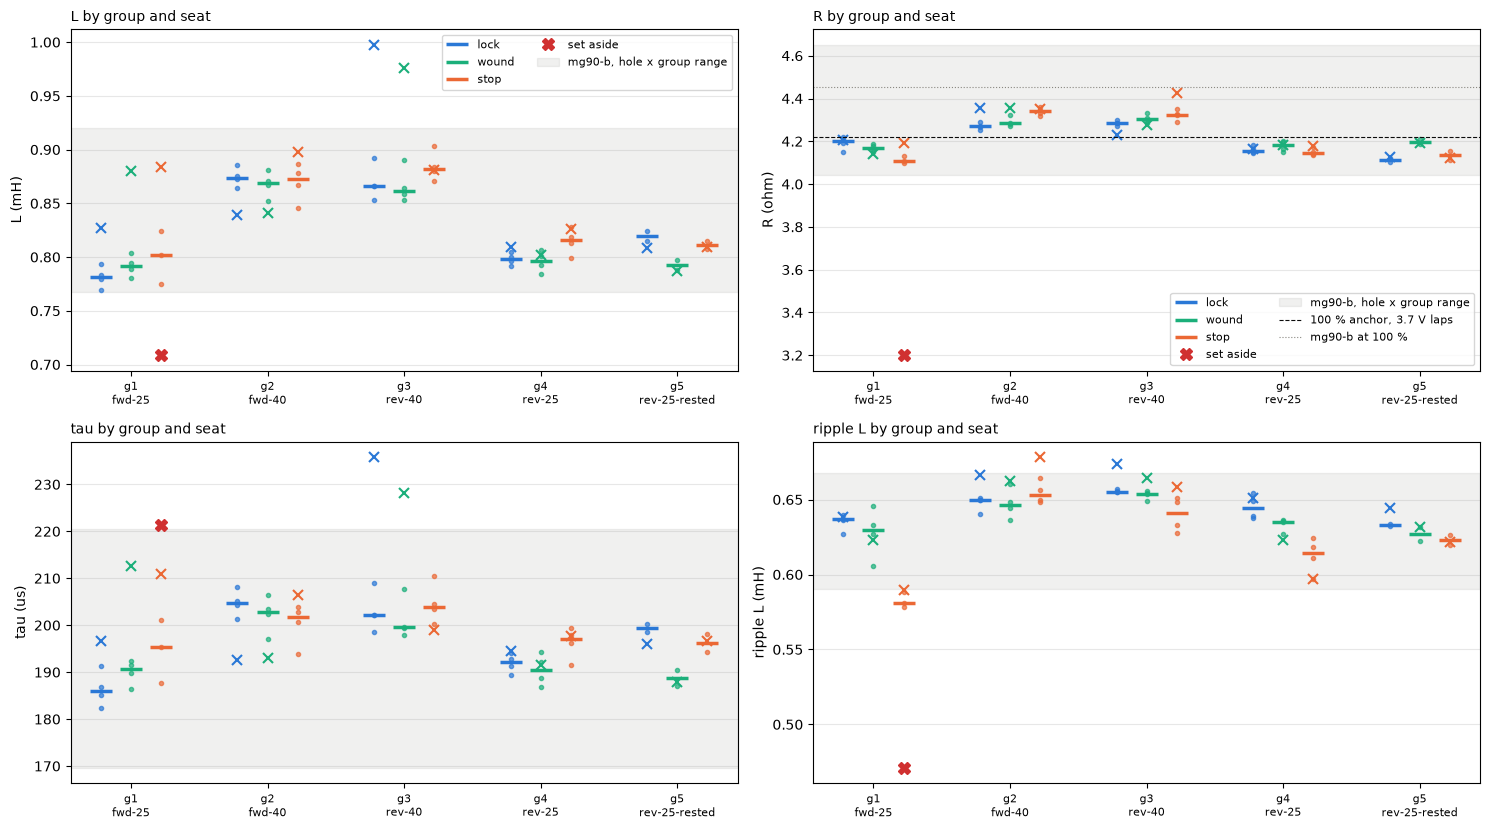

In [31]:
PANELS = (("l_mh", "L", "mH", "l_mh"), ("r_ohm", "R", "ohm", "r_burst_ohm"),
          ("tau_us", "tau", "us", "tau_us"),
          ("l_ripple_mh", "ripple L", "mH", "l_ripple_mh"))
fig, ax = plt.subplots(2, 2, figsize=(15, 8.4))
for axis, (q, lab, unit, key) in zip(ax.flat, PANELS):
    group_panel(axis, q)
    tb = TYPE_B[key]                    # mg90-b, hole x group range
    axis.axhspan(tb["lo"], tb["hi"], color=MUTED, alpha=0.12,
                 label="mg90-b, hole x group range")
    figures.label(axis, y=f"{lab} ({unit})", grid=False)
    axis.set_title(f"{lab} by group and seat", loc="left", fontsize=10)
ax[0, 1].axhline(R_ANCHOR, color=INK, lw=0.8, ls="--",
                 label="100 % anchor, 3.7 V laps")
ax[0, 1].axhline(R_TERM_B, color=MUTED, lw=0.8, ls=":",
                 label="mg90-b at 100 %")
for axis in ax[0]:
    handles, labels = axis.get_legend_handles_labels()
    keep = dict(zip(labels, handles))   # one entry per label
    axis.legend(keep.values(), keep.keys(), fontsize=8, ncol=2)
figures.finish(fig)

In [32]:
GM = OTHERS.groupby(["seat", "group"], sort=False).agg(
    l_mh=("l_mh", "median"), tau_us=("tau_us", "median"),
    r_ohm=("r_ohm", "median"), l_ripple_mh=("l_ripple_mh", "median"),
    resid_mv=("resid_rms_mv", "median")).reset_index()
for seat, g in GM.groupby("seat", sort=False):
    print(f"{seat}: group medians L {g['l_mh'].min():.3f} to "
          f"{g['l_mh'].max():.3f} mH, tau {g['tau_us'].min():.0f} to "
          f"{g['tau_us'].max():.0f} us, R {g['r_ohm'].min():.3f} to "
          f"{g['r_ohm'].max():.3f} ohm, ripple L "
          f"{g['l_ripple_mh'].min():.3f} to {g['l_ripple_mh'].max():.3f} "
          f"mH, residual {g['resid_mv'].min():.0f} to "
          f"{g['resid_mv'].max():.0f} mV per pair")

lock: group medians L 0.781 to 0.874 mH, tau 186 to 205 us, R 4.112 to 4.285 ohm, ripple L 0.633 to 0.655 mH, residual 19 to 23 mV per pair
wound: group medians L 0.792 to 0.869 mH, tau 189 to 203 us, R 4.167 to 4.305 ohm, ripple L 0.627 to 0.654 mH, residual 16 to 23 mV per pair
stop: group medians L 0.788 to 0.882 mH, tau 196 to 204 us, R 4.102 to 4.339 ohm, ripple L 0.580 to 0.653 mH, residual 16 to 25 mV per pair


The group medians at all three seats sit inside mg90-b's band on $L$ and $\tau$, and on $R$ near its bottom. On $L_\mathrm{ripple}$ every group sits inside it but the stop's forward 25 % group, at 0.580 mH. The 40 % groups read $L$ about 9 % over the 25 % groups at every seat, as on the type. The burst $R$ sits under the 100 % anchor at 25 % and over it at 40 %, which the section on the time scale takes up. That group holds the burst set aside, and its median here keeps that burst in, as the group table of this section does. Every seat number below leaves it out.

### What the fit leaves per pair

The full fit's residual per period pair, the median over each seat's bursts after the first, by duty, with the burst-to-burst standard error. A pair whose median sits within two standard errors of zero is in the flat band.

In [33]:
for (seat, pct), g in OTHERS.groupby(["seat", "pct"]):
    R_ = np.vstack([fit(PER[i])["resid_mv"] for i in g["idx"]])
    med = np.median(R_, axis=0)                 # mV per pair
    se = R_.std(axis=0, ddof=1) / np.sqrt(len(R_))
    flat = np.abs(med) < 2 * se
    print(f"{seat} {pct} %: " + " ".join(f"{m:+.0f}" for m in med)
          + " mV | se " + " ".join(f"{s:.0f}" for s in se)
          + " | flat " + "".join("y" if x else "n" for x in flat))

lock 25 %: -31 +30 +24 +6 +3 +2 -14 -17 mV | se 2 5 4 3 4 3 3 3 | flat nnnyyynn
lock 40 %: -31 +30 +23 +11 +1 -12 -12 -12 mV | se 3 3 3 5 4 4 5 3 | flat nnnnynnn
stop 25 %: -25 +17 +24 +15 +0 -8 -11 -10 mV | se 3 4 4 4 3 4 3 3 | flat nnnnyynn
stop 40 %: -33 +26 +26 +13 -6 +0 -13 -14 mV | se 3 5 3 1 3 3 3 3 | flat nnnnyynn
wound 25 %: -25 +21 +22 +11 -4 -5 -10 -11 mV | se 2 3 3 3 2 3 3 4 | flat nnnnyynn
wound 40 %: -34 +26 +27 +18 -5 -6 -8 -15 mV | se 2 2 4 5 6 4 3 2 | flat nnnnyynn


The full fit leaves about 20 mV rms per pair, 16 to 25 mV in the group medians. Its median shape is the same at every seat and duty, -25 to -34 mV on pair 1, +17 to +30 mV on pairs 2 and 3, and -8 to -17 mV on pairs 7 and 8. Pair 5 sits within two standard errors of zero everywhere, pairs 5 and 6 at four of the six seat and duty sets. That is the constant-parameter model not following the rise, stage 2's finding on the type. Every burst carries it, so it cancels in every comparison between bursts.

## The first burst of each group

Each group's first burst over the median of the group's other bursts, in percent, by seat and by the change that came before the group, and its leftover volt-seconds against its group's others' $R$ and $L$. On the left the $L$ jump, on the right the leftover with the others' largest |leftover| as a black tick. The open diamonds are mg90-b's median over its twelve holes with their range.

In [34]:
def jumps(fits):
    # each group's first burst over the median of its other bursts, in
    # percent, for the four quantities, and its leftover
    out = []
    for (seat, group), g in fits.groupby(["seat", "group"], sort=False):
        first, rest = g[g["first"]].iloc[0], g[~g["first"]]
        row = {"seat": seat, "group": group, "pct": first["pct"],
               "sign": first["sign"]}
        for c in QTY:
            row[c] = (first[c] / rest[c].median() - 1) * 100
        row["flux_uvs"] = first["flux_uvs"]
        row["flux_others_max_uvs"] = rest["flux_uvs"].abs().max()
        row["share_1_4_pct"] = (first["flux_pairs_1_4_uvs"]
                                / first["flux_uvs"] * 100)
        row["bound_uvs"] = first["travel_bound_uvs"]
        out.append(row)
    return pd.DataFrame(out)


J = jumps(F)

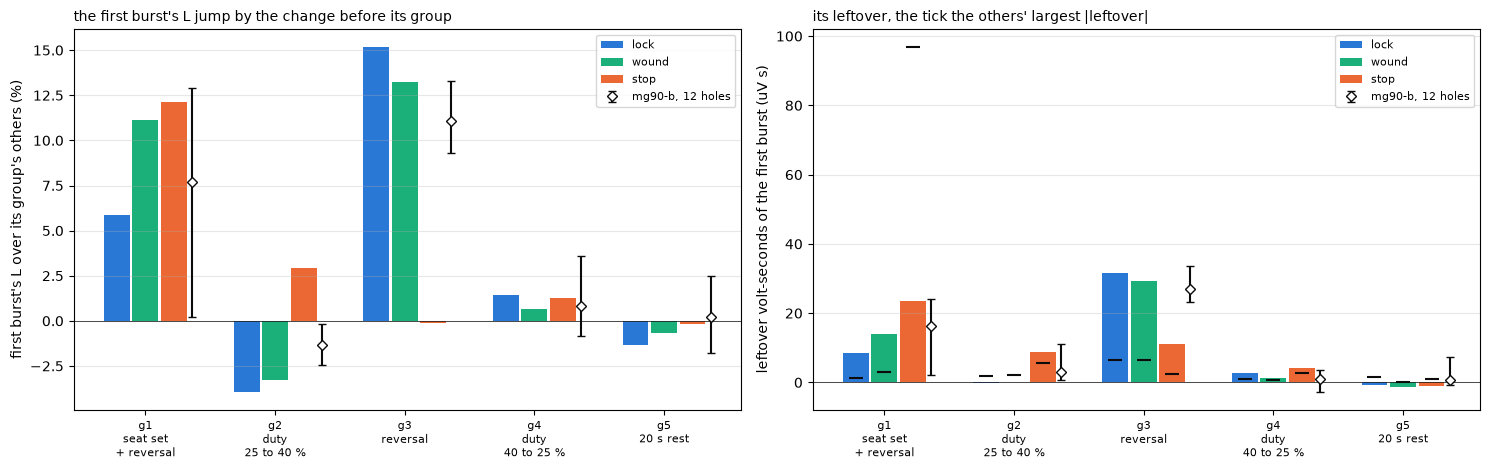

In [35]:
TYPE_CHANGE = ["g1_bar_move_and_reversal", "g2_duty_25_to_40",
               "g3_reversal", "g4_duty_40_to_25", "g5_rest_20s"]
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
x0 = np.arange(len(GROUPS))
for j, seat in enumerate(SEATS):
    r = J[J["seat"] == seat].set_index("group").loc[GROUPS]
    x = x0 + (j - 1) * 0.22
    ax[0].bar(x, r["l_mh"], 0.2, color=SEAT_COLOR[seat], label=seat)
    ax[1].bar(x, r["flux_uvs"], 0.2, color=SEAT_COLOR[seat], label=seat)
    ax[1].plot(x, r["flux_others_max_uvs"], "_", color=INK, ms=10, mew=1.5)
for axis, by in ((ax[0], TYPE_B["l_first_jump_pct_by_change"]),
                 (ax[1], TYPE_B["leftover_flux_uvs_by_change"])):
    keys = TYPE_CHANGE if axis is ax[0] else [g[:2] for g in GROUPS]
    v = np.array([by[k]["value"] for k in keys])
    err = [v - [by[k]["lo"] for k in keys], [by[k]["hi"] for k in keys] - v]
    axis.errorbar(x0 + 0.36, v, yerr=err, fmt="D", ms=5, color=INK,
                  mfc="white", capsize=3, label="mg90-b, 12 holes")
    axis.axhline(0, color=INK, lw=0.5)
    axis.set_xticks(x0, [f"{g[:2]}\n{CHANGE[g]}" for g in GROUPS],
                    fontsize=8)
    axis.grid(alpha=figures.GRID_ALPHA, axis="y")
    axis.legend(fontsize=8)
figures.label(ax[0], y="first burst's L over its group's others (%)",
              grid=False)
figures.label(ax[1], y="leftover volt-seconds of the first burst (uV s)",
              grid=False)
ax[0].set_title("the first burst's L jump by the change before its group",
                loc="left", fontsize=10)
ax[1].set_title("its leftover, the tick the others' largest |leftover|",
                loc="left", fontsize=10)
figures.finish(fig)

In [36]:
for g in GROUPS:
    line = []
    for seat in SEATS:
        r = J[(J["seat"] == seat) & (J["group"] == g)].iloc[0]
        share = r["share_1_4_pct"] if abs(r["flux_uvs"]) > 2 else np.nan
        line.append(f"{seat} L {r['l_mh']:+.1f} tau {r['tau_us']:+.1f} "
                    f"R {r['r_ohm']:+.1f} rip {r['l_ripple_mh']:+.1f}, "
                    f"{r['flux_uvs']:+.1f} uV s (others <= "
                    f"{r['flux_others_max_uvs']:.1f}, 1-4 {share:.0f} %, "
                    f"bound {r['bound_uvs']:.1f})")
    print(f"{g}: " + " | ".join(line))

g1-fwd-25: lock L +5.9 tau +5.7 R +0.1 rip +0.3, +8.6 uV s (others <= 1.3, 1-4 95 %, bound 3.4) | wound L +11.1 tau +11.5 R -0.6 rip -1.2, +14.1 uV s (others <= 2.9, 1-4 88 %, bound 3.3) | stop L +12.1 tau +6.4 R +2.2 rip +1.8, +23.4 uV s (others <= 97.0, 1-4 71 %, bound 3.3)
g2-fwd-40: lock L -4.0 tau -5.9 R +2.1 rip +2.5, -0.3 uV s (others <= 1.9, 1-4 nan %, bound 5.3) | wound L -3.3 tau -4.9 R +1.7 rip +2.4, +0.1 uV s (others <= 2.2, 1-4 nan %, bound 5.3) | stop L +2.9 tau +2.3 R +0.3 rip +3.9, +8.8 uV s (others <= 5.8, 1-4 82 %, bound 5.2)
g3-rev-40: lock L +15.2 tau +16.7 R -1.2 rip +2.8, +31.7 uV s (others <= 6.4, 1-4 84 %, bound 5.0) | wound L +13.2 tau +14.3 R -0.7 rip +1.6, +29.3 uV s (others <= 6.6, 1-4 83 %, bound 5.1) | stop L -0.1 tau -2.4 R +2.3 rip +2.7, +11.0 uV s (others <= 2.4, 1-4 64 %, bound 5.3)
g4-rev-25: lock L +1.4 tau +1.3 R +0.1 rip +1.0, +2.7 uV s (others <= 0.9, 1-4 126 %, bound 3.4) | wound L +0.6 tau +0.6 R +0.1 rip -1.9, +1.2 uV s (others <= 0.6, 1-4 nan 

The reversal with the duty kept, g3, reads the first burst's $L$ 15.2 % over its group's others at the lock and 13.2 % at the wound lock, $\tau$ about the same, $R$ within 1.2 % and $L_\mathrm{ripple}$ within 3 %. Its leftover is 31.7 and 29.3 uV s, against at most 6.6 uV s for the group's other bursts, and 83 to 84 % of it sits in pairs 1 to 4, the first 200 us. A rotor free from rest under the burst's own torque could add at most about 5 uV s. That is the type's signature, mg90-b's 11.1 % (9.3 to 13.3 over the holes) with 27 uV s and mg90-c's 10.3 %, a few points larger here, likely, from two seats.

The duty changes and the rest move $L$ by 4 % or less. The duty-up g2 reads $L$ 4.0 and 3.3 % low and $\tau$ 5.9 and 4.9 % short at the two locks, the type's -1.4 and -3.0 % in the same shape at about twice the size, a candidate. The first group, g1, reads $L$ 5.9 % high at the lock and 11.1 % at the wound lock, with 8.6 and 14.1 uV s.

At the stop the picture differs. Its g3 reads $L$ -0.1 % with 11.0 uV s, 64 % of it in pairs 1 to 4, and its g1 and g2 read leftovers of 23.4 and 8.8 uV s with the group's later bursts not back at zero. The section after the next reads the stop's bursts one by one.

### The leftover per amp

Stage 2 read a reversal's leftover over the old and the new step's currents added, the old and the new current each the median last window current of the group's others. The same for g3 at the two locks.

In [37]:
last = OTHERS.groupby(["seat", "group"])["i_last_a"].median()   # A
PER_AMP = {}
for seat in ("lock", "wound"):          # the two seats a reversal reads
    flux = J[(J["seat"] == seat) & (J["group"] == "g3-rev-40")]
    PER_AMP[seat] = (flux["flux_uvs"].iloc[0]
                     / (last[(seat, "g2-fwd-40")]
                        + last[(seat, "g3-rev-40")]))
    print(f"{seat} g3: {flux['flux_uvs'].iloc[0]:.1f} uV s over "
          f"{last[(seat, 'g2-fwd-40')]:.3f} + "
          f"{last[(seat, 'g3-rev-40')]:.3f} A, "
          f"{PER_AMP[seat]:.0f} uV s/A")
print(f"mg90-b over every reversal "
      f"{TYPE_B['leftover_per_amp_uvs_per_a']['value']:.0f} uV s/A "
      f"({TYPE_B['leftover_per_amp_uvs_per_a']['lo']:.0f} to "
      f"{TYPE_B['leftover_per_amp_uvs_per_a']['hi']:.0f})")

lock g3: 31.7 uV s over 0.370 + 0.370 A, 43 uV s/A
wound g3: 29.3 uV s over 0.371 + 0.370 A, 40 uV s/A
mg90-b over every reversal 34 uV s/A (30 to 46)


Per amp of the old and the new step together the lock's g3 reads 43 uV s/A and the wound lock's 40, against mg90-b's 34 over every reversal it ran, 30 to 46. Stage 2's leading reading of the jump is magnetic history in the iron, the remanence the last current leaves, driven back through by the first burst of the other sign, with moderate confidence. Nothing here changes that reading, and the larger jump on mg90-d is one motor and two seats against twelve holes.

## What the first burst's extra volts amount to

Every burst's leftover against its group's others, in capture order, three groups per seat, with the free-rotor bound beside it. Then the taps before the step, the bridge off. A rotor still turning between bursts would show there as a tap difference, its back-EMF, away from the seat's rest value.

In [38]:
for seat in SEATS:
    for g in ("g1-fwd-25", "g2-fwd-40", "g3-rev-40"):
        sel = F[(F["seat"] == seat) & (F["group"] == g)].sort_values("k")
        print(f"{seat:5s} {g}: " + " ".join(
            f"{v:+6.1f}" for v in sel["flux_uvs"]) + " uV s | bound "
            + " ".join(f"{v:4.1f}" for v in sel["travel_bound_uvs"]))

lock  g1-fwd-25:   +8.6   -0.4   -1.3   -0.4   +0.7 uV s | bound  3.4  3.5  3.5  3.5  3.5
lock  g2-fwd-40:   -0.3   -0.4   +0.0   +0.1   +1.9 uV s | bound  5.3  5.2  5.2  5.2  5.2
lock  g3-rev-40:  +31.7   +6.4   +0.1   -2.1   +0.0 uV s | bound  5.0  5.1  5.2  5.3  5.2
wound g1-fwd-25:  +14.1   +2.9   -0.8   -0.5   -1.1 uV s | bound  3.3  3.5  3.5  3.5  3.5
wound g2-fwd-40:   +0.1   -0.1   -0.7   +0.3   +2.2 uV s | bound  5.3  5.3  5.3  5.3  5.2
wound g3-rev-40:  +29.3   +6.6   +4.0   -1.3   -2.0 uV s | bound  5.1  5.2  5.2  5.3  5.3
stop  g1-fwd-25:  +23.4   +6.6   +3.1   -0.3  -97.0 uV s | bound  3.3  3.5  3.5  3.5  4.2
stop  g2-fwd-40:   +8.8   +4.9   +1.0   -3.7   -5.8 uV s | bound  5.2  5.2  5.2  5.3  5.3
stop  g3-rev-40:  +11.0   -0.3   +0.5   -0.3   +2.4 uV s | bound  5.3  5.3  5.2  5.2  5.2


In [39]:
def prestep(e):
    # the taps before the step, bridge off: sign x (A - B) in mV, its
    # mean over the pre-step half and over each half of it
    df = e["df"]
    m, ph, sh, ta, tb = bu.phase(df, ARR)
    k = np.arange(len(df))
    pre = k < m["step_index"] - PRE_GUARD
    code_ = df["code"].to_numpy(float)
    a_k, b_k = k[ta & pre], k[tb & pre]
    vb = np.interp(a_k, b_k, code_[tb & pre])   # B at A's samples
    volts = e["sign"] * (code_[ta & pre] - vb) / SCALES.terminal_counts_per_v
    half = len(volts) // 2
    # means, not medians: the taps are integers a count apart, about 4 mV,
    # and a median hides anything under a count
    return {"seat": e["seat"], "group": e["group"], "k": e["k"],
            "pre_diff_mv": float(volts.mean() * 1e3),
            "pre_sd_mv": float(volts.std() * 1e3),
            "pre_first_half_mv": float(volts[:half].mean() * 1e3),
            "pre_second_half_mv": float(volts[half:].mean() * 1e3),
            "pre_shunt_sd_counts": float(code_[sh & pre].std())}


P = pd.DataFrame([prestep(e) for _, e in B.iterrows()])
P["less_seat_mv"] = (P["pre_diff_mv"]
                     - P.groupby("seat")["pre_diff_mv"].transform("median"))

In [40]:
for seat, g in P.groupby("seat", sort=False):
    halves = g["pre_first_half_mv"] - g["pre_second_half_mv"]
    print(f"{seat}: pre-step tap difference median "
          f"{g['pre_diff_mv'].median():+.1f} mV, every burst within "
          f"{g['less_seat_mv'].min():+.1f} to {g['less_seat_mv'].max():+.1f}"
          f" mV of it, sd within a burst {g['pre_sd_mv'].median():.1f} mV, "
          f"the halves apart by at most {halves.abs().max():.1f} mV, shunt "
          f"sd {g['pre_shunt_sd_counts'].median():.2f} counts")
sa_pre = P[(P["seat"] == SET_ASIDE[0]) & (P["group"] == SET_ASIDE[1])
           & (P["k"] == SET_ASIDE[2])].iloc[0]
print(f"the burst set aside: {sa_pre['less_seat_mv']:+.1f} mV from its "
      f"seat's median")

lock: pre-step tap difference median +0.0 mV, every burst within -0.6 to +0.4 mV of it, sd within a burst 2.6 mV, the halves apart by at most 0.8 mV, shunt sd 1.15 counts
wound: pre-step tap difference median -0.0 mV, every burst within -0.5 to +0.7 mV of it, sd within a burst 2.6 mV, the halves apart by at most 1.3 mV, shunt sd 1.20 counts
stop: pre-step tap difference median -0.1 mV, every burst within -0.5 to +0.6 mV of it, sd within a burst 2.6 mV, the halves apart by at most 1.1 mV, shunt sd 1.25 counts
the burst set aside: +0.4 mV from its seat's median


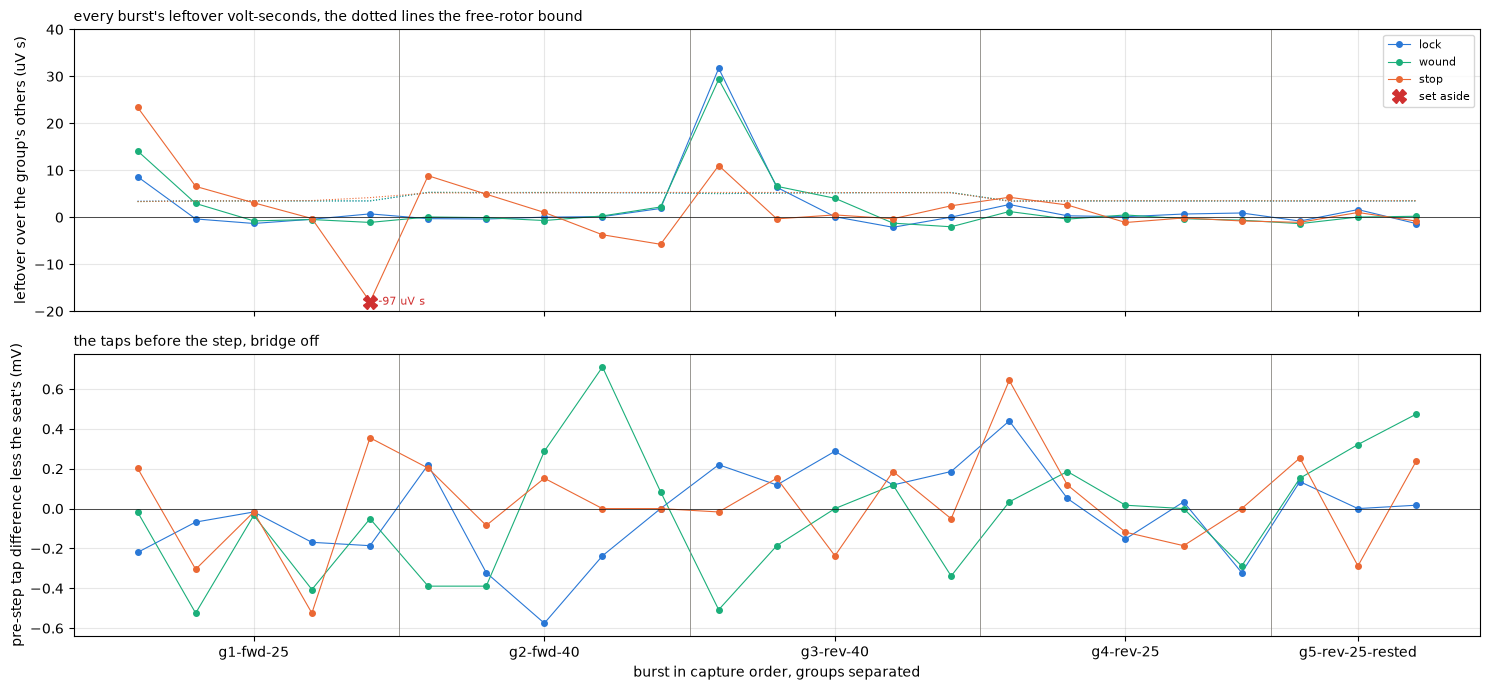

In [41]:
fig, ax = plt.subplots(2, 1, figsize=(15, 7), sharex=True)
for seat in SEATS:
    s = F[F["seat"] == seat].reset_index(drop=True)
    x = np.arange(len(s))               # capture order inside the seat
    y = s["flux_uvs"].clip(lower=-18)   # the set-aside burst at the edge
    ax[0].plot(x, y, "o-", ms=4, lw=0.8, color=SEAT_COLOR[seat],
               label=seat)
    ax[0].plot(x, s["travel_bound_uvs"], ":", lw=0.8,
               color=SEAT_COLOR[seat])
    for xa in x[s["set_aside"]]:
        ax[0].plot(xa, -18, "X", ms=10, color=RED, label="set aside")
        ax[0].annotate(f"{s['flux_uvs'][xa]:.0f} uV s", (xa, -18),
                       xytext=(6, 0), textcoords="offset points",
                       fontsize=8, va="center", color=RED)
    p = P[P["seat"] == seat].reset_index(drop=True)
    ax[1].plot(x, p["less_seat_mv"], "o-", ms=4, lw=0.8,
               color=SEAT_COLOR[seat], label=seat)
sizes = F[F["seat"] == "lock"].groupby("group", sort=False).size()
bounds = np.r_[0, np.cumsum(sizes.loc[GROUPS].to_numpy())]
for axis in ax:
    for b in bounds[1:-1]:
        axis.axvline(b - 0.5, color=MUTED, lw=0.6)
    axis.axhline(0, color=INK, lw=0.5)
ax[0].set_ylim(-20, 40)
ax[0].set_xticks((bounds[:-1] + bounds[1:]) / 2 - 0.5, GROUPS, fontsize=8)
figures.label(ax[0], y="leftover over the group's others (uV s)")
figures.label(ax[1], x="burst in capture order, groups separated",
              y="pre-step tap difference less the seat's (mV)")
ax[0].set_title("every burst's leftover volt-seconds, the dotted lines the "
                "free-rotor bound", loc="left", fontsize=10)
ax[1].set_title("the taps before the step, bridge off", loc="left",
                fontsize=10)
ax[0].legend(fontsize=8)
figures.finish(fig)

At both locks a group's first burst carries the leftover and the later bursts come back to zero, within +/-2.2 uV s from the fourth burst on. At the stop the two forward groups do not settle that way. The forward 25 % group reads +23.4, +6.6, +3.1 and -0.3 uV s before the burst set aside, 71 % of the first burst's leftover in pairs 1 to 4 against 83 to 95 % at the locks. The forward 40 % group repeats it, +8.8, +4.9, +1.0, -3.7 and -5.8. The reverse groups at the stop read like the lock's.

At the low stop the forward direction is the one away from the stop, the direction the rotor is free to take up through the train's play. A rotor creeping forward through the play under each forward burst's torque gives a positive leftover that decays burst by burst, likely. The pot reads 2 to 3 counts throughout, on the ADC's rail, so the creep does not show in `pos`, and a motor-side creep of a few milliradians is far under a count at the output through 308:1 anyway.

The taps before the step show no rotor still turning between bursts. Every burst's pre-step difference sits within +/-0.7 mV of its seat's median, a sixth of a count, the two halves of the pre-step stretch within 1.3 mV of each other, and the burst set aside among them at +0.4 mV.

The burst set aside is a different matter. Its current is a fifth high from the first period, within 50 us of the step, and a free rotor's back-EMF over the whole burst, its travel bound, is 4.2 uV s against the burst's -97 uV s of leftover. Its $R$ reads 3.20 ohm, its $L_\mathrm{ripple}$ 0.47 mH and its early $R$ 3.39 ohm, each about 0.78 of its group's others. That is the winding's topology changing, not motion during the burst, with high confidence on the timing. The leading reading is a brush bridging two commutator segments after the creep carried the commutator into a bridging zone, shorting one coil, with moderate confidence. The teardown found three equal coils in a delta, so one coil shorted leaves 6 ohm in parallel with 6 against 6 in parallel with 12, 3 against 4 ohm, a ratio of 0.75. The other reading is the other brush's contact lifting and re-seating. Bursts at the stop with the forward direction left out, or the set repeated with the ratio read again, would separate them.

The reversal's first burst at the stop, g3 after g2, reads $L$ -0.1 % with 11.0 uV s, where both locks read 13 to 15 % with 29 to 32 uV s. The magnetic-history jump is absent there, and a smaller leftover of the rotor-travel shape, growing through the burst, is there instead. The leading reading, low to moderate, is that the g2 bursts walked the rotor through some commutator angle and g3's first burst spent its first periods winding the play back toward the stop. The g2 group's others read $L$ like the lock's, so a biased reference does not carry it. A reverse-only burst set into the stop, or the reversal at the high stop where the pot can see a count of creep, would test it.

The stop's reverse groups g4 and g5, pressed into the stop with the train wound, read $L$ 0.814 and 0.811 mH, $\tau$ 197 and 196 us and $R$ 4.147 and 4.134 ohm, within 2 % of the lock's reverse 25 % groups, and their first bursts read like the lock's. Those are the stop's clean bursts.

## R and L against the time scale

The fit over the first $p$ pairs for $p$ from 3 to 8, every burst after the first, the median and the 16 to 84 % band per seat and duty. A one-pole winding draws flat lines. The dashed line is the 100 % anchor.

In [42]:
rows = []
for _, f in OTHERS.iterrows():          # every burst after the first
    table = PER[f["idx"]]
    for p in range(EARLY_PAIRS, len(table)):
        short = fit(table, p)
        rows.append({"seat": f["seat"], "pct": f["pct"], "sign": f["sign"],
                     "pairs": p, "r_ohm": short["r_ohm"],
                     "l_mh": short["l_mh"]})
SCAN = pd.DataFrame(rows)
SL = []
for (seat, pct), g in SCAN.groupby(["seat", "pct"]):
    m = g.groupby("pairs")[["l_mh", "r_ohm"]].median()
    SL.append({"seat": seat, "pct": pct,
               "l_slide_pct": (m["l_mh"].iloc[-1] / m["l_mh"].iloc[0] - 1)
               * 100,
               "r_slide_pct": (m["r_ohm"].iloc[-1] / m["r_ohm"].iloc[0] - 1)
               * 100})
SL = pd.DataFrame(SL)

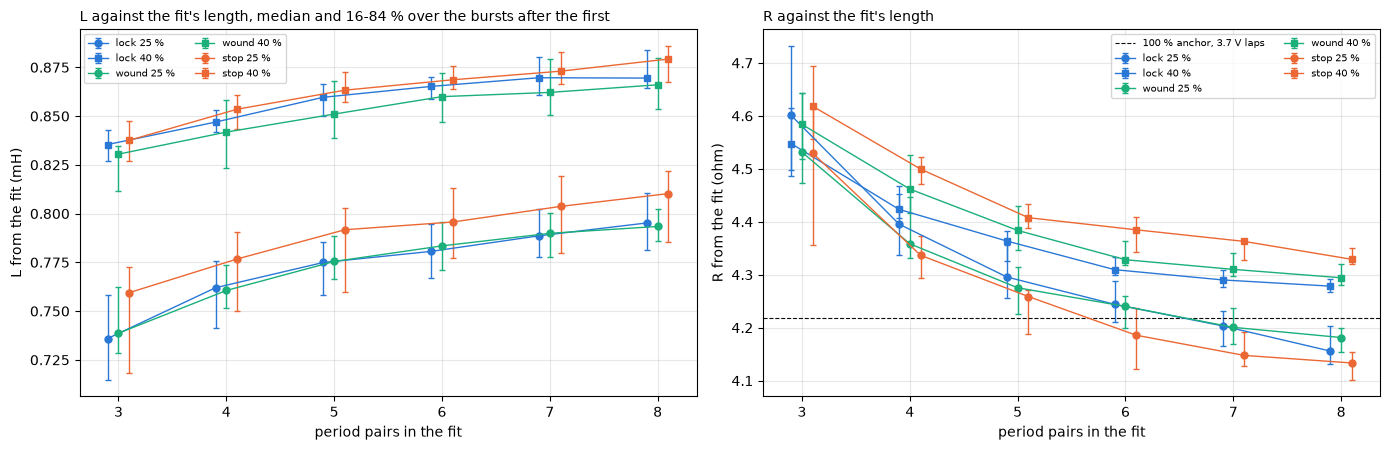

In [43]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
for j, seat in enumerate(SEATS):
    for pct in DUTIES:
        g = SCAN[(SCAN["seat"] == seat) & (SCAN["pct"] == pct)]
        by = g.groupby("pairs")
        for axis, q in ((ax[0], "l_mh"), (ax[1], "r_ohm")):
            m = by[q].median()
            lo, hi = by[q].quantile(0.16), by[q].quantile(0.84)
            axis.errorbar(m.index + (j - 1) * 0.1, m, yerr=[m - lo, hi - m],
                          fmt=DUTY_MARK[pct] + "-", ms=5, lw=1, capsize=2,
                          color=SEAT_COLOR[seat], label=f"{seat} {pct} %")
ax[1].axhline(R_ANCHOR, color=INK, lw=0.8, ls="--",
              label="100 % anchor, 3.7 V laps")
figures.label(ax[0], x="period pairs in the fit", y="L from the fit (mH)")
figures.label(ax[1], x="period pairs in the fit", y="R from the fit (ohm)")
ax[0].set_title("L against the fit's length, median and 16-84 % over the "
                "bursts after the first", loc="left", fontsize=10)
ax[1].set_title("R against the fit's length", loc="left", fontsize=10)
ax[0].legend(fontsize=7, ncol=2)
ax[1].legend(fontsize=7, ncol=2)
figures.finish(fig)

In [44]:
MODEL_SLIDE = MM_B["l_slide_model_pct"]     # mg90-b, hole 11
for _, r in SL.iterrows():
    t = MODEL_SLIDE[str(r["pct"])]
    print(f"{r['seat']} {r['pct']} %: from 3 to 8 pairs L "
          f"{r['l_slide_pct']:+.1f} %, R {r['r_slide_pct']:+.1f} %; "
          f"mg90-b hole 11 data {t['data']['value']:+.1f} %, its model "
          f"{t['model']['value']:+.1f} %")
early = OTHERS.groupby("pct")["early_r_ohm"].median()
print("the early fit's R, 3 pairs, every seat: " + ", ".join(
    f"{p} % {v:.3f} ohm ({(v / R_ANCHOR - 1) * 100:+.1f} % on the anchor)"
    for p, v in early.items()))

lock 25 %: from 3 to 8 pairs L +8.1 %, R -9.7 %; mg90-b hole 11 data +8.1 %, its model +8.4 %
lock 40 %: from 3 to 8 pairs L +4.1 %, R -5.9 %; mg90-b hole 11 data +5.6 %, its model +7.3 %
stop 25 %: from 3 to 8 pairs L +6.7 %, R -8.7 %; mg90-b hole 11 data +8.1 %, its model +8.4 %
stop 40 %: from 3 to 8 pairs L +5.0 %, R -6.3 %; mg90-b hole 11 data +5.6 %, its model +7.3 %
wound 25 %: from 3 to 8 pairs L +7.4 %, R -7.7 %; mg90-b hole 11 data +8.1 %, its model +8.4 %
wound 40 %: from 3 to 8 pairs L +4.3 %, R -6.3 %; mg90-b hole 11 data +5.6 %, its model +7.3 %
the early fit's R, 3 pairs, every seat: 25 % 4.543 ohm (+7.7 % on the anchor), 40 % 4.584 ohm (+8.6 % on the anchor)


$R$ and $L$ slide with the fit's length at every seat and duty. At the lock $L$ rises 8.1 % and $R$ falls 9.7 % from 3 to 8 pairs at 25 %, and 4.1 and 5.9 % at 40 %. The wound lock and the stop read the same within 2 points, and mg90-b at hole 11 read +8.1 and +5.6 % on $L$. The burst is not one pole on this motor either, with high confidence, and the burst $R$ is the end of the slide, not the winding's resistance. Over the first three pairs $R$ reads 7 to 9 % over the 100 % anchor, where the type's early $R$ sat 5.8 to 6.0 % over its rest-resistance.

### A constant drop as a third term

A brush contact drops a voltage that does not scale with the current. One burst's volts and currents move together and leave such a term undetermined, so both duties of a seat and sign go into one fit, $V_n = V_0 + R\,i + L\,di/dt$, with $V_0$ ("V zero") the constant drop.

In [45]:
def pair_rows(grp, cols):
    # the stacked design of every period pair of a set of bursts
    X, Y = [], []
    for _, f in grp.iterrows():
        t = PER[f["idx"]]
        i, v = t["i_a"].to_numpy(), t["v_v"].to_numpy()
        im, di = (i[1:] + i[:-1]) / 2, np.diff(i) / T_S
        X.append(cols(im, di))
        Y.append(v[:-1])
    return np.vstack(X), np.concatenate(Y)


def rms_mv(X, Y, coef):
    return float(np.sqrt(np.mean((Y - X @ coef) ** 2)) * 1e3)


rows = []
for (seat, sign), grp in OTHERS.groupby(["seat", "sign"]):
    X, Y = pair_rows(grp, lambda im, di: np.c_[np.ones(len(im)), im, di])
    coef = np.linalg.lstsq(X, Y, rcond=None)[0]       # V0, R, L
    two = np.linalg.lstsq(X[:, 1:], Y, rcond=None)[0]  # R, L alone
    rows.append({"seat": seat, "sign": sign, "v0_v": coef[0],
                 "r_ohm": coef[1] / K, "l_mh": coef[2] / K * 1e3,
                 "resid2_mv": rms_mv(X[:, 1:], Y, two),
                 "resid3_mv": rms_mv(X, Y, coef)})
V0 = pd.DataFrame(rows)
for _, r in V0.iterrows():
    print(f"{r['seat']} {SIGN[r['sign']]}: V0 {r['v0_v']:+.3f} V, R "
          f"{r['r_ohm']:.3f} ohm, L {r['l_mh']:.3f} mH, residual "
          f"{r['resid2_mv']:.0f} -> {r['resid3_mv']:.0f} mV")

lock rev: V0 -0.143 V, R 4.658 ohm, L 0.922 mH, residual 41 -> 26 mV
lock fwd: V0 -0.149 V, R 4.678 ohm, L 0.924 mH, residual 43 -> 30 mV
stop rev: V0 -0.176 V, R 4.776 ohm, L 0.953 mH, residual 44 -> 23 mV
stop fwd: V0 -0.294 V, R 4.994 ohm, L 0.987 mH, residual 117 -> 103 mV
wound rev: V0 -0.149 V, R 4.706 ohm, L 0.918 mH, residual 40 -> 25 mV
wound fwd: V0 -0.151 V, R 4.686 ohm, L 0.923 mH, residual 41 -> 26 mV


The drop comes out at -0.14 to -0.15 V at both locks, both signs, with $R$ at 4.66 to 4.71 ohm and $L$ at 0.92 mH. A contact drop is positive, so this is the wrong sign, as on the type at -0.12 V, and the third term is absorbing the slide rather than measuring a contact. The stop reads -0.18 V reverse and -0.29 V forward, the forward fit holding the burst set aside.

### An inductance that grows with the current

The other reading of the slide is an inductance that depends on the current, $L = L_0 + L_1\,i$ at the pair's mean current, over all pairs per seat and duty.

In [46]:
rows = []
for (seat, pct), grp in OTHERS.groupby(["seat", "pct"]):
    X, Y = pair_rows(grp, lambda im, di: np.c_[im, di, im * di])
    coef = np.linalg.lstsq(X, Y, rcond=None)[0]       # R, L0, L1
    two = np.linalg.lstsq(X[:, :2], Y, rcond=None)[0]
    rows.append({"seat": seat, "pct": pct, "r_ohm": coef[0] / K,
                 "l0_mh": coef[1] / K * 1e3,
                 "l1_mh_per_a": coef[2] / K * 1e3,
                 "resid2_mv": rms_mv(X[:, :2], Y, two),
                 "resid3_mv": rms_mv(X, Y, coef)})
LOFI = pd.DataFrame(rows)
for _, r in LOFI.iterrows():
    print(f"{r['seat']} {r['pct']} %: R {r['r_ohm']:.3f} ohm, L0 "
          f"{r['l0_mh']:.3f} mH, L1 {r['l1_mh_per_a']:+.2f} mH/A, residual "
          f"{r['resid2_mv']:.0f} -> {r['resid3_mv']:.0f} mV")

lock 25 %: R 3.923 ohm, L0 0.663 mH, L1 +1.54 mH/A, residual 23 -> 16 mV
lock 40 %: R 4.141 ohm, L0 0.805 mH, L1 +0.53 mH/A, residual 23 -> 17 mV
stop 25 %: R 4.271 ohm, L0 0.934 mH, L1 -1.60 mH/A, residual 80 -> 77 mV
stop 40 %: R 4.177 ohm, L0 0.801 mH, L1 +0.59 mH/A, residual 25 -> 17 mV
wound 25 %: R 3.999 ohm, L0 0.692 mH, L1 +1.17 mH/A, residual 19 -> 13 mV
wound 40 %: R 4.150 ohm, L0 0.794 mH, L1 +0.58 mH/A, residual 24 -> 17 mV


At 25 % $L_0$ reads 0.66 to 0.69 mH with $L_1$ at +1.2 to +1.5 mH/A at the two locks, and at 40 % $L_0$ 0.79 to 0.81 mH with $L_1$ +0.5 to +0.6 mH/A at every seat. The residual per pair drops from 19 to 25 mV to 13 to 17 mV. The type at 8 pairs read 0.654 + 1.72 $i$ and 0.772 + 0.85 $i$. The stop's 25 % fit, with the burst set aside in it, reads -1.6 mH/A at 77 mV and is not a number.

## The window and the crest sample

What the firmware's crest sample is in these bursts. The bridge's window middle, halfway between its ON edge (tap ON lag after the commanded start) and its OFF edge (OFF lag after the commanded end), is where the period table reads each window's current. The crest shunt sample closes at its own instant from sample-timing. For every held burst after the first, each period's window line is read at both instants, and the raw shunt sample nearest the crest instant is read against the line at the middle, as the firmware would see it.

In [47]:
def window_periods(f):
    # one burst's windows: the line at the middle and at the crest
    # instant, the nearest raw sample, and the window's own L per period
    e = B.loc[f["idx"]]
    s, _, half = bu.samples(e["df"], BOARD, "crest")
    zero = bu.zero(e["df"], ARR)
    a, b = -half + LAGS["tap_on"], half + LAGS["off"]   # bridge's edges
    s = s[(s["n"] >= 0) & s["full"]]
    settled = (s["tc"] >= -half + LAGS["settle"]) & (s["tc"] <= half)
    table = PER[f["idx"]]
    l_rip = ripple_l(table, R_ANCHOR)
    rows = []
    for n, g in s.groupby("n"):
        sh = g[(g["stream"] == "sh") & settled[g.index]]
        line = np.polyfit(sh["tc"], sh["code"] - zero, 1)
        i_mid = np.polyval(line, (a + b) / 2) / SCALES.counts_per_a
        i_crest = np.polyval(line, CREST_AT) / SCALES.counts_per_a
        near = sh.iloc[(sh["tc"] - CREST_AT).abs().argsort().iloc[:1]]
        i_raw = float((near["code"].iloc[0] - zero) / SCALES.counts_per_a)
        rows.append({"seat": f["seat"], "pct": f["pct"],
                     "sign": f["sign"], "group": f["group"], "k": f["k"],
                     "n": n, "i_mid_a": i_mid,
                     "line_less_mid_ma": (i_crest - i_mid) * 1e3,
                     "raw_less_mid_ma": (i_raw - i_mid) * 1e3,
                     "raw_tc": float(near["tc"].iloc[0]),
                     "mid_tick": (a + b) / 2,
                     "l_ripple_mh": l_rip[n] if n < len(l_rip) else np.nan})
    return rows


W = pd.DataFrame([r for _, f in HELD.iterrows()
                  for r in window_periods(f)])

In [48]:
print(f"the bridge's window middle at {W['mid_tick'].iloc[0]:+.0f} ticks "
      f"from the crest, the crest shunt sample at {CREST_AT:+d}")
CREST_READ = {}
for pct, g in W.groupby("pct"):
    line, raw = g["line_less_mid_ma"], g["raw_less_mid_ma"]
    CREST_READ[pct] = (line.median(), line.quantile(0.16),
                       line.quantile(0.84))
    print(f"{pct} %: the window line at the crest instant less the line "
          f"at the middle {line.median():+.2f} mA (16-84 % "
          f"{line.quantile(0.16):+.2f} to {line.quantile(0.84):+.2f}), "
          f"the nearest raw sample less the middle {raw.median():+.2f} mA "
          f"(16-84 % {raw.quantile(0.16):+.2f} to "
          f"{raw.quantile(0.84):+.2f}), that sample at "
          f"{g['raw_tc'].min():+.0f} to {g['raw_tc'].max():+.0f} ticks")

the bridge's window middle at +27 ticks from the crest, the crest shunt sample at +31
25 %: the window line at the crest instant less the line at the middle +0.56 mA (16-84 % +0.53 to +0.59), the nearest raw sample less the middle -0.47 mA (16-84 % -3.63 to +6.53), that sample at -21 to +82 ticks
40 %: the window line at the crest instant less the line at the middle +0.46 mA (16-84 % +0.43 to +0.48), the nearest raw sample less the middle +2.10 mA (16-84 % -1.32 to +6.58), that sample at -21 to +81 ticks


The window middle sits at +27 ticks from the crest, half the sum of the ON lag of 40 ticks and the OFF lag of 14, and the crest sample closes at +31. Over every held burst the window line at +31 reads +0.56 mA over the line at the middle at 25 % and +0.46 mA at 40 %. The nearest raw sample reads -0.5 and +2.1 mA in the median, with a 16 to 84 % spread about 8 to 10 mA wide, one sample's noise of a few counts. So under slow decay the crest sample is the window's mean to half a milliamp, and the window's mean is the period mean of a two-segment ripple. Whatever a crest reads over a meter's mean is therefore not the ripple's geometry. It is what the shunt sees inside the window that the brake interval returns, the type model's loss across $L$, its current-dependent $L$ and its rung. These bursts measure the shape terms of that model and not the loss.

### The window's own L by period

The window's own $L$ period by period, the median over the held bursts of each seat and duty, against the window current at the middle.

In [49]:
BYN = (W.groupby(["seat", "pct", "n"])
       .agg(i_ma=("i_mid_a", lambda x: x.median() * 1e3),
            l=("l_ripple_mh", "median"),
            lo=("l_ripple_mh", lambda x: x.quantile(0.16)),
            hi=("l_ripple_mh", lambda x: x.quantile(0.84)))
       .reset_index())
for (seat, pct), g in BYN.groupby(["seat", "pct"]):
    print(f"{seat} {pct} %: " + " ".join(
        f"{r['i_ma']:.0f}mA:{r['l']:.3f}" for _, r in g.iterrows()))

lock 25 %: 56mA:0.697 108mA:0.687 144mA:0.646 171mA:0.641 192mA:0.666 208mA:0.656 220mA:0.645 230mA:0.635 238mA:0.639
lock 40 %: 78mA:0.770 158mA:0.778 216mA:0.744 261mA:0.694 295mA:0.668 322mA:0.655 342mA:0.653 358mA:0.655 370mA:0.648
stop 25 %: 58mA:0.711 109mA:0.687 146mA:0.635 172mA:0.629 193mA:0.640 210mA:0.625 223mA:0.620 233mA:0.611 240mA:0.597
stop 40 %: 78mA:0.770 159mA:0.779 217mA:0.737 261mA:0.688 296mA:0.654 323mA:0.652 343mA:0.654 359mA:0.650 371mA:0.641
wound 25 %: 57mA:0.693 109mA:0.671 145mA:0.638 172mA:0.649 193mA:0.657 210mA:0.652 222mA:0.635 231mA:0.629 239mA:0.623
wound 40 %: 79mA:0.763 160mA:0.775 218mA:0.729 262mA:0.686 296mA:0.663 323mA:0.651 344mA:0.653 360mA:0.649 371mA:0.651


In [50]:
LIR = {}       # the window L on its current, one line per seat
for seat, g in W[W["n"] >= 1].groupby("seat"):
    x, y = g["i_mid_a"].to_numpy(), g["l_ripple_mh"].to_numpy()
    ok = np.isfinite(y)
    X = np.c_[np.ones(ok.sum()), x[ok]]         # intercept, slope
    coef, res, *_ = np.linalg.lstsq(X, y[ok], rcond=None)
    s2 = res[0] / (ok.sum() - 2)                # residual variance
    se = np.sqrt(np.diag(s2 * np.linalg.inv(X.T @ X)))
    LIR[seat] = {"at_0_mh": coef[0], "per_a_mh": coef[1],
                 "se_per_a_mh": se[1], "rms_uh": np.sqrt(s2) * 1e3}
    print(f"{seat}: L_ripple = {coef[0]:.3f} ({se[0]:.3f}) "
          f"{coef[1]:+.3f} ({se[1]:.3f}) x i, rms {np.sqrt(s2) * 1e3:.0f} "
          f"uH over {ok.sum()} periods, {x[ok].min() * 1e3:.0f} to "
          f"{x[ok].max() * 1e3:.0f} mA")

lock: L_ripple = 0.697 (0.011) -0.128 (0.044) x i, rms 39 uH over 144 periods, 107 to 371 mA
stop: L_ripple = 0.681 (0.014) -0.115 (0.054) x i, rms 48 uH over 136 periods, 107 to 372 mA
wound: L_ripple = 0.687 (0.010) -0.112 (0.041) x i, rms 37 uH over 144 periods, 107 to 372 mA


The window's $L$ starts at 0.69 to 0.71 mH at 25 % and 0.76 to 0.78 mH at 40 %, and settles to 0.60 to 0.65 mH by the burst's end, as on the type, 0.69 and 0.75 settling to 0.62. At the same current the two duties read different $L$. Near 215 mA, period 6 at 25 % reads 0.645 mH and period 2 at 40 % about 0.74. So the fall is with time since the step, not with current, high confidence on three seats. A line of the window $L$ on its current over periods 1 and later reads -0.13 +/- 0.04 mH/A at the lock, the time trend in disguise. On the window's time scale $L$ reads 0.64 to 0.65 mH at 230 to 370 mA with no current dependence beyond the settling. The current dependence, about +1 mH/A, lives in the slow part the period fit reads, likely, as on the type.

### The gap between the window and the fit

$L_\mathrm{ripple}$ over the period fit's $L$, the two signs' medians averaged, with the range of the group medians, by seat and duty. On bridge-states' fixed inductors the same ratio is the method's own gap.

In [51]:
RF = []
for seat in SEATS:
    for pct in DUTIES:
        g = HELD[(HELD["seat"] == seat) & (HELD["pct"] == pct)]
        ratios = [g[g["sign"] == s]["l_ripple_mh"].median()
                  / g[g["sign"] == s]["l_mh"].median() for s in (1, -1)]
        gm = g.groupby("group").agg(r=("l_ripple_mh", "median"),
                                    f=("l_mh", "median"))
        gr = gm["r"] / gm["f"]                  # per group
        RF.append({"seat": seat, "pct": pct, "ratio": np.mean(ratios),
                   "lo": gr.min(), "hi": gr.max()})
RF = pd.DataFrame(RF)
for _, r in RF.iterrows():
    tb = TYPE_B["ripple_over_fit"][str(r["pct"])]["value"]
    tc = TYPE_C["ripple_over_fit"][str(r["pct"])]["value"]
    ind = TYPE_B["ripple_over_fit_inductors"][str(r["pct"])]
    print(f"{r['seat']} {r['pct']} %: {r['ratio']:.3f} ({r['lo']:.3f} to "
          f"{r['hi']:.3f}); mg90-b {tb:.3f}, mg90-c {tc:.3f}, the "
          f"inductors {ind['lo']:.3f} to {ind['hi']:.3f}")

lock 25 %: 0.805 (0.772 to 0.815); mg90-b 0.765, mg90-c 0.768, the inductors 0.970 to 0.996
lock 40 %: 0.750 (0.744 to 0.757); mg90-b 0.713, mg90-c 0.715, the inductors 0.911 to 0.959
wound 25 %: 0.796 (0.791 to 0.797); mg90-b 0.765, mg90-c 0.768, the inductors 0.970 to 0.996
wound 40 %: 0.751 (0.744 to 0.759); mg90-b 0.713, mg90-c 0.715, the inductors 0.911 to 0.959
stop 25 %: 0.742 (0.724 to 0.768); mg90-b 0.765, mg90-c 0.768, the inductors 0.970 to 0.996
stop 40 %: 0.737 (0.726 to 0.748); mg90-b 0.713, mg90-c 0.715, the inductors 0.911 to 0.959


In [52]:
def ripple_fit_panel(axis):
    # the ripple L over the fit by seat and duty, against the type motors
    # and bridge-states' inductors
    for j, seat in enumerate(SEATS):
        r = RF[RF["seat"] == seat].set_index("pct").loc[list(DUTIES)]
        axis.errorbar(np.arange(2) + (j - 1) * 0.15, r["ratio"],
                      yerr=[r["ratio"] - r["lo"], r["hi"] - r["ratio"]],
                      fmt="o", ms=6, capsize=3, color=SEAT_COLOR[seat],
                      label=seat)
    for x, pct in enumerate(DUTIES):
        first = x == 0
        b = TYPE_B["ripple_over_fit"][str(pct)]["value"]
        c = TYPE_C["ripple_over_fit"][str(pct)]["value"]
        axis.plot(x + 0.32, b, "D", color=INK, mfc="white", ms=6,
                  label="mg90-b" if first else None)
        axis.plot(x + 0.38, c, "^", color=INK, mfc="white", ms=6,
                  label="mg90-c" if first else None)
        ind = TYPE_B["ripple_over_fit_inductors"][str(pct)]
        axis.fill_between([x - 0.4, x + 0.4], ind["lo"], ind["hi"],
                          color=MUTED, alpha=0.25,
                          label="bridge-states' inductors" if first else None)
    axis.set_xticks(range(2), [f"{p} %" for p in DUTIES])
    axis.set_ylim(0.6, 1.05)
    figures.label(axis, y="ripple L over the period fit's L", grid=False)
    axis.grid(alpha=figures.GRID_ALPHA, axis="y")
    axis.legend(fontsize=8, ncol=2, loc="lower center")
    axis.set_title("the gap between the window and the fit, by seat",
                   loc="left", fontsize=10)

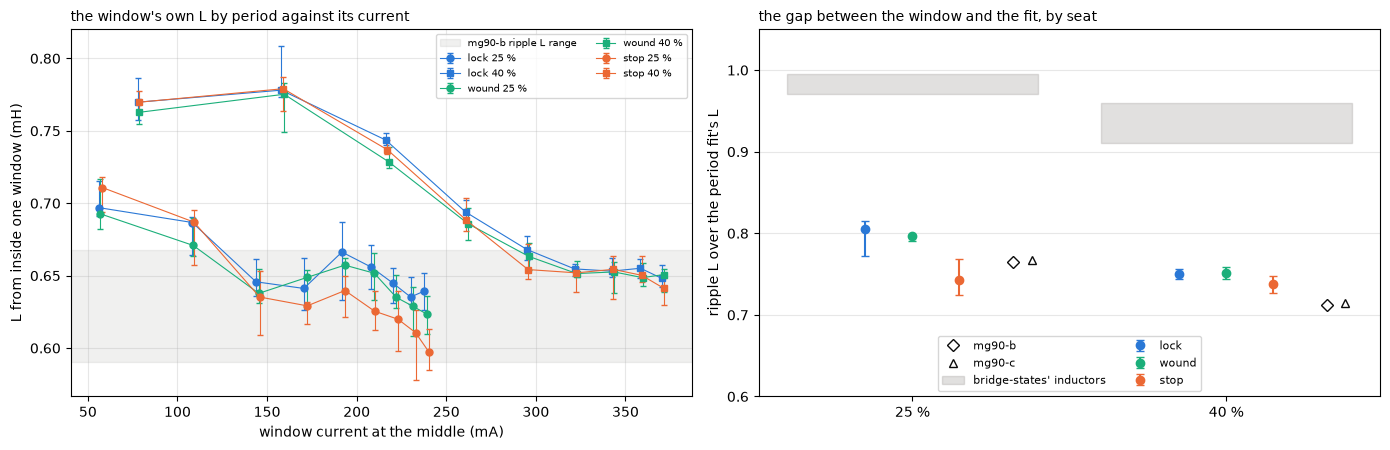

In [53]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
for seat in SEATS:
    for pct in DUTIES:
        g = BYN[(BYN["seat"] == seat) & (BYN["pct"] == pct)]
        ax[0].errorbar(g["i_ma"], g["l"], yerr=[g["l"] - g["lo"],
                                                g["hi"] - g["l"]],
                       fmt=DUTY_MARK[pct] + "-", ms=5, lw=0.8, capsize=2,
                       color=SEAT_COLOR[seat], label=f"{seat} {pct} %")
ax[0].axhspan(TYPE_B["l_ripple_mh"]["lo"], TYPE_B["l_ripple_mh"]["hi"],
              color=MUTED, alpha=0.12, label="mg90-b ripple L range")
figures.label(ax[0], x="window current at the middle (mA)",
              y="L from inside one window (mH)")
ax[0].set_title("the window's own L by period against its current",
                loc="left", fontsize=10)
ax[0].legend(fontsize=7, ncol=2)
ripple_fit_panel(ax[1])
figures.finish(fig)

On the left the window's $L$ walks down from its first period to its last at every seat and duty, and the 25 % and 40 % lines do not lie on one curve of current. On the right the ratio reads 0.805 (0.772 to 0.815 over the groups) at 25 % and 0.750 (0.744 to 0.757) at 40 % at the lock, 0.796 and 0.751 at the wound lock, and 0.742 and 0.737 at the stop. mg90-b reads 0.765 and 0.713, mg90-c 0.768 and 0.715, and bridge-states' inductors 0.970 to 0.996 and 0.911 to 0.959. The gap is the motor's, 20 to 26 %, with high confidence. At both lock seats it is 3 to 5 points smaller than the type's at both duties, a candidate from one motor. Under the type model the gap is set by $G$, $L(i)$ and the rung together, so a smaller gap reads as a somewhat smaller loss or rung on this motor, low confidence.

## The window model carried from the type, and the held stall

The loss conductance is not identifiable from slow-decay bursts without the window simulator. Motor-model identified $G$ within one form of the model and not across forms, 1.8 to 4.0 mS by form. This notebook is held to inductance's estimators, so the window model handed on is the type's, from mg90-b's motor-model and bemf-coast results.

In [54]:
G_LOCKED = MM_B["motor_g_locked_fast_ms"]     # mS, the locked burst fit
G_JOINT = MM_B["motor_g_locked_ms"]           # mS, the joint fit
G_SPIN = MM_B["g_spin_ms"]                    # mS, the spinning motor
L0, RAY = MM_B["motor_l0_mh"], MM_B["motor_rayleigh_per_a"]


def rng_(q, f="{:.2f}"):
    # a carried quantity as "value (lo to hi)"
    return (f"{f.format(q['value'])} ({f.format(q['lo'])} to "
            f"{f.format(q['hi'])})")


print(f"mg90-b window model: L0 {rng_(L0, '{:.3f}')} mH, Rayleigh "
      f"{rng_(RAY)} per A, G locked {rng_(G_LOCKED)} mS (joint "
      f"{G_JOINT['value']:.2f}), G spinning {rng_(G_SPIN)} mS")
print(f"bemf-coast's reading term {G_READ * 1e3:.2f} mA per V of window "
      "volts, by duty " + ", ".join(
          f"{d} {q['value'] * 1e3:.2f}"
          for d, q in BEMF_B["reading_term_by_duty"].items()))
for rail, by in MM_B["crest_less_mean_ma"].items():
    print(f"crest less mean at {rail}: " + ", ".join(
        f"{d} {q['value']:.1f}" for d, q in by.items()) + " mA")

mg90-b window model: L0 0.505 (0.501 to 0.542) mH, Rayleigh 2.91 (2.12 to 3.37) per A, G locked 2.49 (1.77 to 4.00) mS (joint 2.29), G spinning 3.35 (2.84 to 4.73) mS
bemf-coast's reading term 4.29 mA per V of window volts, by duty 20 % 4.32, 30 % 4.33, 40 % 4.21, 60 % 2.78, 80 % 1.58, 100 % -0.03
crest less mean at 3.7 V: 10 % 13.6, 15 % 14.0, 20 % 14.2, 30 % 14.2, 40 % 13.4, 50 % 12.1, 60 % 10.3, 70 % 8.1, 80 % 5.7, 90 % 3.1 mA
crest less mean at 5 V: 10 % 18.4, 15 % 19.0, 20 % 19.4, 30 % 19.4, 40 % 18.4, 50 % 16.5, 60 % 14.0, 70 % 10.9, 80 % 7.6, 90 % 4.2 mA
crest less mean at 7.4 V: 10 % 27.3, 15 % 28.3, 20 % 29.0, 30 % 29.1, 40 % 27.6, 50 % 24.8, 60 % 20.9, 70 % 16.3, 80 % 11.3, 90 % 6.1 mA
crest less mean at 8.4 V: 10 % 31.1, 15 % 32.3, 20 % 33.1, 30 % 33.2, 40 % 31.6, 50 % 28.3, 60 % 23.8, 70 % 18.5, 80 % 12.8, 90 % 6.9 mA


The type's model, carried as is. $L_0$ 0.505 mH with a Rayleigh term of 2.9 per A, $G$ locked 2.49 mS from the fast fit (1.77 to 4.00, joint 2.29), $G$ spinning 3.35 mS, the crest-less-mean table by rail and duty, and the meter's reading term of 4.29 mA per volt of window volts at 20 to 40 %, falling to zero at 100 %. Those were measured on the bare motor spinning at 64 to 560 rev/s with a meter in series, at 15 to 100 % duty and 3.7 to 7.4 V, and in the locked bursts of the first half millisecond after a step. $k$ and the edges are stage 1's.

### The held stall

The steady form of the loss term for a held rotor is $\Delta = G\,(1 - D)\,V_\mathrm{on}$ ("delta"), the crest's excess over the period mean, with $D$ the duty. The shunt sees $G\,v_L$ inside the window, $v_L = (1 - D)\,V_\mathrm{on}$ in continuous conduction, and the brake interval returns it. On that form a held $G$ moves $V_\mathrm{eff}/I_\mathrm{crest}$ with the rail by about $-(R/I)\,G$ ohm per volt, so the sag laps' flat slope over $-R/I$ is the held $G$ they allow.

In [55]:
DR_DG = -R_LAP / I_LAP                  # ohm per V of rail, per S of G
G_HOLD = SLOPE / DR_DG * 1e3            # mS, the held G the slope reads
G_HOLD_SE = SLOPE_SE / abs(DR_DG) * 1e3
print(f"the sag laps' slope {SLOPE:+.4f} +/- {SLOPE_SE:.4f} ohm/V reads "
      f"a held G of {G_HOLD:.2f} +/- {G_HOLD_SE:.2f} mS, under "
      f"{G_HOLD + 2 * G_HOLD_SE:.2f} mS at 2 sigma")
for name, g in (("locked burst", G_LOCKED), ("spinning", G_SPIN)):
    pred = DR_DG * g["value"] * 1e-3    # ohm/V the type's G predicts
    print(f"the type's {name} G {g['value']:.2f} mS predicts "
          f"{pred:+.4f} ohm/V, {(pred - SLOPE) / SLOPE_SE:+.1f} sigma "
          f"from the laps")

the sag laps' slope -0.0055 +/- 0.0071 ohm/V reads a held G of 0.42 +/- 0.54 mS, under 1.50 mS at 2 sigma
the type's locked burst G 2.49 mS predicts -0.0328 ohm/V, -3.9 sigma from the laps
the type's spinning G 3.35 mS predicts -0.0440 ohm/V, -5.4 sigma from the laps


The 13 locked laps at the low stop read a held $G$ of 0.42 +/- 0.54 mS, under 1.5 mS at 2 sigma. The type's locked burst $G$ of 2.49 mS predicts -0.033 ohm per volt, 3.9 sigma from the laps, its spinning 3.35 mS -0.044, and the meter's 4.29 mA per volt -0.068 ohm per volt, the sag notebook's figure. So the locked hold at the end stop shows at most a third of the type's locked-burst loss and a fifth of its spinning term, likely, from one sitting. The window model as the type has it does not describe a held stall at 18 to 25 %, and the sag finding and this reading agree. Two readings are alive.

1. The burst's $G$ is a transient of the flux build-up in the first two time constants, eddy currents in the rotor iron and the case answering the step, and not a steady shunt loss. The spinning motor's larger term is then driven by rotation, the commutation and the slot-frequency flux swing. A held rotor at steady state reads close to the mean. Leading, moderate confidence. One long locked burst, 5 to 10 ms at 25 % with the free-running ADC, would show whether the gap between the window and the fit and the early $R$'s excess relax toward one pole as the periods go on.
2. A crest offset that does not depend on the rail masks the term in the sag laps. They run one current at every rail, so an offset and a per-volt term do not separate there. Alive, low to moderate confidence. Two levels at one rail into the same seat, the resistance notebook's stop chain at 1.2 and 1.8 V effective, read against the 100 % anchor, would separate them.

### The 100 % anchor against the stop laps

With no reading term, the sag laps' $V_\mathrm{eff}/I_\mathrm{crest}$ at their current and the 100 % laps' $R$ at theirs differ by a contact drop $V_0$ that closes the two. The same with the crest's over-read taken out under the type's locked $G$ and under the meter's term, at the laps' middle duty and window volts.

In [56]:
HOLD_OFF_SHARE = 0.78   # 1 - D at the sag laps' middle duty, about 22 %
HOLD_V_ON = 6.9         # V, their window volts, middle of 5.7 to 8.1 V
I_100 = float(GRADED["i_a"].mean())     # A, the 100 % laps' current
READINGS = (("no reading term", 0.0),
            (f"type locked G {G_LOCKED['value']:.2f} mS",
             G_LOCKED["value"] * 1e-3 * HOLD_OFF_SHARE * HOLD_V_ON),
            (f"type meter term {G_READ * 1e3:.2f} mA/V",
             G_READ * HOLD_V_ON))
V0_CLOSE = {}
for name, over in READINGS:             # over: the crest's excess, A
    i_true = I_LAP - over               # the laps' mean current
    r_app = R_LAP * I_LAP / i_true      # V_eff over that current
    v0 = (r_app - R_ANCHOR) / (1 / i_true - 1 / I_100)
    V0_CLOSE[name] = v0
    print(f"{name}: crest over-read {over * 1e3:.0f} mA, V_eff / I "
          f"{r_app:.3f} ohm against the anchor's {R_ANCHOR:.3f} at "
          f"{I_100:.3f} A, a contact drop V0 {v0:+.3f} V")
print(f"mg90-b's V0 {RR_B['v0_brush_v']['value']:.2f} V "
      f"({RR_B['v0_brush_v']['lo']:.2f} to {RR_B['v0_brush_v']['hi']:.2f})")

no reading term: crest over-read 0 mA, V_eff / I 4.344 ohm against the anchor's 4.219 at 0.754 A, a contact drop V0 +0.074 V
type locked G 2.49 mS: crest over-read 13 mA, V_eff / I 4.528 ohm against the anchor's 4.219 at 0.754 A, a contact drop V0 +0.169 V
type meter term 4.29 mA/V: crest over-read 30 mA, V_eff / I 4.771 ohm against the anchor's 4.219 at 0.754 A, a contact drop V0 +0.277 V
mg90-b's V0 0.06 V (0.00 to 0.50)


With no term, the sag laps' 4.344 ohm at 0.330 A and the 100 % laps' 4.219 ohm at 0.754 A close with a contact drop of +0.074 V, against the type's 0.06 V (0 to 0.5), a consistent pair. With the type's locked $G$ the crest would over-read 13 mA and $V_0$ would have to be +0.17 V, and with the meter's term 30 mA and +0.28 V. The no-term reading is the one consistent with the type's $V_0$, moderate confidence, on two seats with the 100 % laps warm at 0.7 J and the commutator angle moving $R$ by about 3 %.

### What the resistance notebook's stop section takes

The resistance plan's stop chain runs 24 and 36 % on 5 V, $V_\mathrm{on}$ about 4.85 V, with lap currents of 0.28 and 0.43 A at the anchor's $R$. Below, the crest's excess over the mean at those two duties under each reading, in milliamps and in percent of the lap current.

In [57]:
STOP_LEVELS = ((24, 1.2), (36, 1.8))    # %, V effective, the stop chain
STOP_V_ON = 4.85                        # V, the window volts on 5 V
rows = []
for pct, v_eff in STOP_LEVELS:
    i_lap = v_eff / R_ANCHOR            # A, the lap at the anchor's R
    for name, g_ms, per_v in (
            ("hold bound", G_HOLD, None),
            ("hold bound + 2 sigma", G_HOLD + 2 * G_HOLD_SE, None),
            ("type locked burst G", G_LOCKED["value"], None),
            ("type spinning G", G_SPIN["value"], None),
            ("type meter per volt", None, G_READ * 1e3)):
        delta = (g_ms * 1e-3 * (1 - pct / 100) * STOP_V_ON if per_v is None
                 else per_v * 1e-3 * STOP_V_ON)          # A
        rows.append({"duty_pct": pct, "i_lap_a": i_lap, "reading": name,
                     "crest_less_mean_ma": delta * 1e3,
                     "pct_of_lap": delta / i_lap * 100})
TAB = pd.DataFrame(rows)

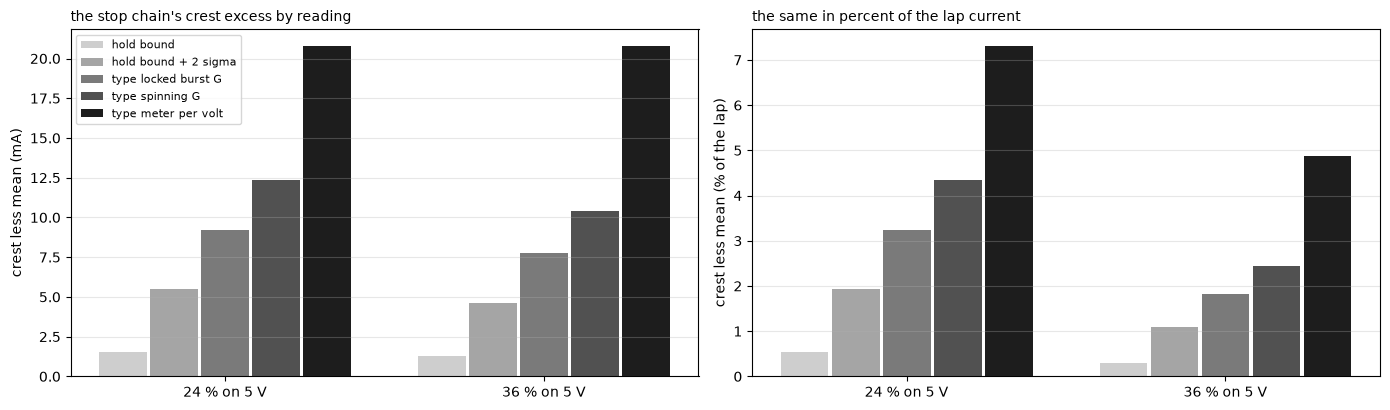

24 %: hold bound 1.5 mA (0.5 %), hold bound + 2 sigma 5.5 mA (1.9 %), type locked burst G 9.2 mA (3.2 %), type spinning G 12.3 mA (4.3 %), type meter per volt 20.8 mA (7.3 %)
36 %: hold bound 1.3 mA (0.3 %), hold bound + 2 sigma 4.6 mA (1.1 %), type locked burst G 7.7 mA (1.8 %), type spinning G 10.4 mA (2.4 %), type meter per volt 20.8 mA (4.9 %)


In [58]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
names = list(dict.fromkeys(TAB["reading"]))
shade = figures.shades("Greys", len(names), lo=0.3, hi=0.9)
for j, name in enumerate(names):
    t = TAB[TAB["reading"] == name]
    x = np.arange(len(STOP_LEVELS)) + (j - 2) * 0.16
    for axis, col in ((ax[0], "crest_less_mean_ma"), (ax[1], "pct_of_lap")):
        axis.bar(x, t[col], 0.15, color=shade[j], label=name)
for axis in ax:
    axis.set_xticks(range(len(STOP_LEVELS)),
                    [f"{p} % on 5 V" for p, _ in STOP_LEVELS])
    axis.grid(alpha=figures.GRID_ALPHA, axis="y")
figures.label(ax[0], y="crest less mean (mA)", grid=False)
figures.label(ax[1], y="crest less mean (% of the lap)", grid=False)
ax[0].set_title("the stop chain's crest excess by reading", loc="left",
                fontsize=10)
ax[1].set_title("the same in percent of the lap current", loc="left",
                fontsize=10)
ax[0].legend(fontsize=8)
figures.finish(fig)
for pct, _ in STOP_LEVELS:
    t = TAB[TAB["duty_pct"] == pct].set_index("reading")
    print(f"{pct} %: " + ", ".join(
        f"{n} {r['crest_less_mean_ma']:.1f} mA ({r['pct_of_lap']:.1f} %)"
        for n, r in t.iterrows()))

Under this stage's held bound the correction is 1.5 +/- 2.0 mA at 24 %, 0.5 % of the lap, and 1.3 +/- 1.8 mA at 36 %, 0.3 %. Under the type's locked $G$ it would be 9.2 and 7.7 mA, 3.2 and 1.8 %, under its spinning $G$ 12.3 and 10.4 mA, and under the meter's per-volt term 20.8 mA, 7.3 and 4.9 %. The resistance notebook's stop section should apply no correction, carry the +2 sigma bound, 5.5 and 4.6 mA or 1.9 and 1.1 % of the lap, as the systematic on its $R$, and read its two-level line's $V_0$ against the anchor as the check of the second reading. If the ladder needs a term at speed, it is the type's spinning table per volt of window volts, a carried type number and not this servo's. The resistance notebook's chains on three rails later showed that a crest term is required at partial duty, so the no-correction recommendation in this paragraph is superseded. The paragraph stays as the record of this notebook's reading.

## The three seats

Each seat's median over its held bursts after the first, per duty, with a bootstrap over the bursts, and the pairwise differences in percent of the first seat of the pair with their bootstrap sigma. The bootstrap sigma is the scatter of the bursts within a seat only, four to eight bursts a side.

In [59]:
RNG = np.random.default_rng(SEED)


def boot_median(x):
    # the median of x and BOOT_DRAWS medians of resamples of it
    x = np.asarray(x, float)
    draws = np.median(RNG.choice(x, (BOOT_DRAWS, len(x))), axis=1)
    return np.median(x), draws


COMPARED = {**QTY, "l_pinned_mh": "pinned L", "early_r_ohm": "early R",
            "i_last_a": "I_last"}
PAIRS = (("lock", "wound"), ("lock", "stop"), ("wound", "stop"))
rows = []
for q, lab in COMPARED.items():
    for pct in DUTIES:
        reads = {}
        for seat in SEATS:
            sel = HELD[(HELD["seat"] == seat) & (HELD["pct"] == pct)]
            reads[seat] = boot_median(sel[q])
            med, d = reads[seat]
            rows.append({"col": q, "quantity": lab, "pct": pct,
                         "seat": seat, "n": len(sel), "median": med,
                         "lo16": np.quantile(d, 0.16),
                         "hi84": np.quantile(d, 0.84)})
        for a, b in PAIRS:
            dm = reads[b][0] - reads[a][0]
            se = (reads[b][1] - reads[a][1]).std()
            rows.append({"col": q, "quantity": lab, "pct": pct,
                         "pair": f"{b} - {a}",
                         "diff_pct": dm / reads[a][0] * 100,
                         "sigma": dm / se if se > 0 else np.nan})
SC = pd.DataFrame(rows)

In [60]:
UNIT = {"L": "mH", "tau": "us", "R": "ohm", "ripple L": "mH",
        "pinned L": "mH", "early R": "ohm", "I_last": "A"}
for (lab, pct), g in SC.groupby(["quantity", "pct"], sort=False):
    seats = g[g["seat"].notna()]
    pairs = g[g["pair"].notna()]
    print(f"{lab} {pct} %: " + ", ".join(
        f"{r['seat']} {r['median']:.3f} [{r['lo16']:.3f}, {r['hi84']:.3f}]"
        for _, r in seats.iterrows()) + f" {UNIT[lab]} | " + ", ".join(
        f"{r['pair']} {r['diff_pct']:+.1f} % ({r['sigma']:+.1f} s)"
        for _, r in pairs.iterrows()))

L 25 %: lock 0.795 [0.792, 0.800], wound 0.793 [0.789, 0.797], stop 0.813 [0.808, 0.815] mH | wound - lock -0.2 % (-0.3 s), stop - lock +2.2 % (+2.2 s), stop - wound +2.5 % (+2.9 s)
L 40 %: lock 0.869 [0.866, 0.875], wound 0.866 [0.860, 0.871], stop 0.879 [0.873, 0.883] mH | wound - lock -0.4 % (-0.4 s), stop - lock +1.1 % (+1.3 s), stop - wound +1.5 % (+1.7 s)
tau 25 %: lock 191.344 [189.368, 192.765], wound 190.174 [188.767, 191.539], stop 196.282 [195.303, 197.820] us | wound - lock -0.6 % (-0.5 s), stop - lock +2.6 % (+1.9 s), stop - wound +3.2 % (+2.9 s)
tau 40 %: lock 203.217 [202.098, 205.058], wound 201.036 [199.499, 203.399], stop 203.105 [201.489, 203.875] us | wound - lock -1.1 % (-0.8 s), stop - lock -0.1 % (-0.1 s), stop - wound +1.0 % (+0.8 s)
R 25 %: lock 4.156 [4.150, 4.182], wound 4.181 [4.166, 4.187], stop 4.137 [4.130, 4.142] ohm | wound - lock +0.6 % (+1.4 s), stop - lock -0.5 % (-1.0 s), stop - wound -1.1 % (-2.7 s)
R 40 %: lock 4.278 [4.271, 4.285], wound 4.294 [4

In [61]:
POOLED = {}
for q, lab in QTY.items():
    out = []
    for seat in SEATS:
        sel = HELD[HELD["seat"] == seat]
        gm = sel.groupby("group")[q].median()
        POOLED[(seat, q)] = (sel[q].median(), gm.min(), gm.max())
        out.append(f"{seat} {sel[q].median():.3f} ({gm.min():.3f} to "
                   f"{gm.max():.3f})")
    print(f"{lab}, both duties: " + "; ".join(out))
ALL_GM = HELD.groupby(["seat", "group"])     # every seat's groups
print(f"every seat pooled, {len(HELD)} bursts: " + ", ".join(
    f"{lab} {HELD[q].median():.3f} ({ALL_GM[q].median().min():.3f} to "
    f"{ALL_GM[q].median().max():.3f})" for q, lab in QTY.items()))

L, both duties: lock 0.820 (0.781 to 0.874); wound 0.805 (0.792 to 0.869); stop 0.828 (0.802 to 0.882)
tau, both duties: lock 198.505 (186.003 to 204.684); wound 193.340 (188.829 to 202.905); stop 199.351 (195.303 to 203.947)
R, both duties: lock 4.217 (4.112 to 4.285); wound 4.206 (4.167 to 4.305); stop 4.171 (4.106 to 4.339)
ripple L, both duties: lock 0.645 (0.633 to 0.655); wound 0.636 (0.627 to 0.654); stop 0.626 (0.581 to 0.653)
every seat pooled, 53 bursts: L 0.825 (0.781 to 0.882), tau 197.863 (186.003 to 204.684), R 4.211 (4.106 to 4.339), ripple L 0.638 (0.581 to 0.655)


The wound lock reads the lock's $L$, $\tau$ and $R$ within 1.1 % at both duties, 0.3 to 1.4 sigma, nothing. The stop reads $L$ 2.2 % over the lock at 25 % (2.2 sigma) and 1.1 % at 40 % (1.3), $\tau$ 2.6 % and -0.1 %, and $R$ -0.5 % at 25 % and +1.2 % at 40 %, the one difference among $L$, $\tau$ and $R$ past 4 sigma. The stop's 25 % ripple $L$ reads 4.2 % low (2.2 sigma) and its 40 % ripple $L$ 0.6 %.

The type's twelve holes put the commutator angle's spread at about 8 % on $L$, 3 % on $R$ at rest and 13 % on the burst $R$, so a seat-to-seat difference of 1 to 2.5 % is what two angles give. The bootstrap sigma carries only the bursts' scatter within a seat. So the three seats agree on $L$, $\tau$ and the burst $R$ within 2.5 %, inside the angle's spread, and nothing separates a seat effect from the angle, likely. No seat correction follows. The stop's low 25 % ripple $L$ sits in its forward group only, the group whose bursts walked, so it is not a property of the seat.

The bursts after the first read the same at the wound lock as at the plain lock. To the first burst of the first group, forward after the reverse press 40 s before, it adds about +5 uV s, $L$ +11.1 % and 14.1 uV s at the wound lock against +5.9 % and 8.6 uV s at the plain lock, 88 % of it in pairs 1 to 4, against a free-rotor bound of 3.3 uV s. The lock's g1 also followed a reversal, the resistance laps' reverse about 20 s earlier. A train wound by the press and letting go into the lock as the forward burst starts predicts a few uV s of forward EMF in the first burst, and so does a slightly larger remanence from the press's 300 ms. The two do not separate on one group, a candidate. The reversal g3 reads the same at both lock seats, so a wound train does not change the reversal's first burst.

For laps pressed into the stop, the stop's own into-the-stop groups are the reference, and they agree with the lock within the angle's spread, so the lock's constants carry to the stop with no seat correction, likely. What the stop adds is the walk in the free direction. A lap or burst set at the stop has to press into it, never away. A forward lap at the low stop, or a reverse one at the high stop, is a rotor walking through the play with the commutator angle drifting, the burst $R$ and the ripple $L$ both moving, and one burst in ten here read a different winding. The sag stop laps all pressed into the stop and are not affected.

## The seats themselves

The pot through the three sittings, from every manifest probe and every burst's meta. The lock and the wound lock share the left panel, the stop the right.

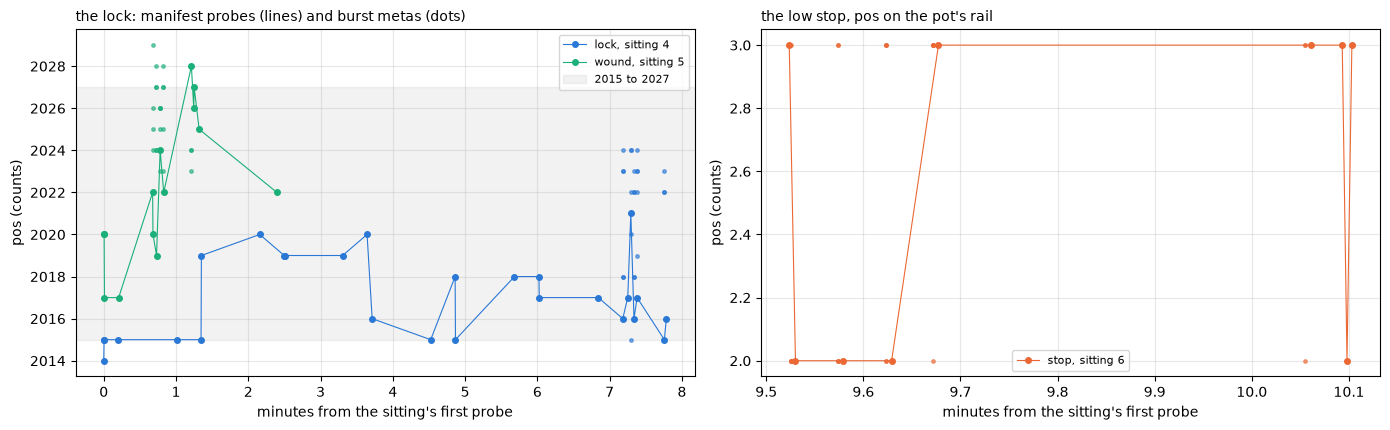

In [62]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
for seat, sitting in SITTING.items():
    pr = manifest_probes(sitting)
    t0 = pr["t_host"].iloc[0]           # the sitting's first probe
    axis = ax[1] if seat == "stop" else ax[0]
    near = (pr["pos"] < 100) if seat == "stop" else (
        (pr["pos"] > 1500) & (pr["pos"] < 2500))
    sel = pr[near]                      # the probes at this seat
    axis.plot((sel["t_host"] - t0) / 60, sel["pos"], "o-", ms=4, lw=0.8,
              color=SEAT_COLOR[seat], label=f"{seat}, sitting {sitting}")
    mk = marks(seat)
    t_g = {g: mk[mk["mark"] == g]["t_host"].iloc[0] for g in GROUPS}
    bb = F[F["seat"] == seat]
    axis.plot([(t_g[g] - t0) / 60 for g in bb["group"]], bb["pos"], ".",
              ms=5, alpha=0.6, color=SEAT_COLOR[seat])
ax[0].axhspan(2015, 2027, color=MUTED, alpha=0.1, label="2015 to 2027")
for axis in ax:
    figures.label(axis, x="minutes from the sitting's first probe",
                  y="pos (counts)")
    axis.legend(fontsize=8)
ax[0].set_title("the lock: manifest probes (lines) and burst metas (dots)",
                loc="left", fontsize=10)
ax[1].set_title("the low stop, pos on the pot's rail", loc="left",
                fontsize=10)
figures.finish(fig)

In [63]:
for seat in SEATS:
    st = seats_table(seat)
    groups = B[B["seat"] == seat].groupby("group", sort=False)["pos"]
    print(f"{seat}: seats.csv " + ", ".join(map(str, st["pos"]))
          + "; burst metas " + ", ".join(
              f"{g[:2]} {p.min()}-{p.max()}" for g, p in groups))
WALK = pd.concat([manifest_probes(s).assign(sitting=s) for s in (4, 5)])
for s, g in WALK.groupby("sitting"):
    print(f"sitting {s}: every probe {g['pos'].min()} to {g['pos'].max()}")
LOCK_SPAN = (WALK["pos"].min(), WALK["pos"].max())
print(f"sittings 4 and 5: {LOCK_SPAN[0]} to {LOCK_SPAN[1]}, "
      f"{LOCK_SPAN[1] - LOCK_SPAN[0]} counts")
NTC_C = {}
for s in SITTING.values():
    raw = manifest_probes(s)["ntc_raw"]
    NTC_C[s] = float(BOARD.ntc_c_beta(np.array([raw.median()]))[0])
    print(f"sitting {s}: board NTC raw {raw.min()} to {raw.max()}, "
          f"median {NTC_C[s]:.1f} C by the board's beta")

lock: seats.csv 2016, 2016; burst metas g1 2018-2024, g2 2015-2024, g3 2018-2023, g4 2019-2024, g5 2022-2023
wound: seats.csv 2017, 2022, 2026; burst metas g1 2022-2029, g2 2024-2028, g3 2023-2026, g4 2023-2028, g5 2023-2024
stop: seats.csv 3, 3; burst metas g1 2-3, g2 2-3, g3 2-3, g4 2-3, g5 2-3
sitting 4: every probe 2014 to 2021
sitting 5: every probe 2017 to 2028
sittings 4 and 5: 2014 to 2028, 14 counts
sitting 4: board NTC raw 1983 to 2002, median 26.3 C by the board's beta
sitting 5: board NTC raw 1996 to 2038, median 25.5 C by the board's beta
sitting 6: board NTC raw 1971 to 2019, median 26.5 C by the board's beta


At the lock in sitting 4 the pot read 2014 at center and 2015 with the lock on, 2015 to 2020 through the six 100 % laps, 0 to 5 counts per lap, 2016 before the bursts, 2015 to 2024 in the burst metas and 2016 after. The lock holds the horn within about 5 counts, 0.25 degrees at the horn, under 0.75 A laps and 0.37 A bursts. A count at the horn is 1.6 rad at the motor through 308:1, far more than the 20 mrad a first burst's leftover would need, yet the first burst keeps the type's size and shape, pairs 1 to 4, so the lock's give does not enter the jump, as stage 2 concluded from the time shape.

At the wound lock in sitting 5 the pot read 2020 at center and with the lock on, 2017 before the press, 2022 after the 24 % reverse press, 2019 to 2028 through the groups' probes and 2022 to 2029 in the burst metas, and 2026 after the bursts, 9 counts from before the press, one under the runner's 10-count rule. The walk follows the drive's sign, toward 2022 under reverse and toward 2029 under forward, which reads as the lock's own give of about 0.4 degrees at the horn and not a slip, likely.

Every probe of sittings 4 and 5 sits at 2014 to 2028. Each sitting re-seats the lock on a freshly centered horn, 2014 and 2020 at center, so the span is two seatings plus the give under drive, 14 counts or 0.7 degrees at the horn. The 10-count rule is adequate for the bursts, since nothing in the sections above moved with `pos`, and marginal for a sitting that presses the lock.

At the stop in sitting 6 the 24 % reverse press took the horn from 2043 to `pos` 3, and it read 2 to 3 through every group and after. That reading is blind. The stopper flexes 60 to 84 counts under a lap and the pot's rail sits 86 counts under the free stop, so `pos` says only "at the rail". The current traces say the rotor was held in the reverse groups, with the rest floor before the step, leftovers within +/-2.6 uV s and fits like the lock's, and walking in the forward ones.

The board's NTC read 25.5 to 26.5 C in the medians of the three sittings, so nothing above is a temperature effect, at copper's 0.39 % per C under 0.4 % across sittings.

## Results

The lock's values per duty against the two type motors' result files, in percent of each, the ripple $L$ pooled over both duties as the type files carry it.

In [64]:
LOCK_HELD = HELD[HELD["seat"] == "lock"]   # the headline seat
GRADE = (("L", "l_mh_by_duty", "l_mh"), ("tau", "tau_us_by_duty", "tau_us"),
         ("burst R", "r_burst_ohm_by_duty", "r_ohm"),
         ("pinned L", "l_mh_r_pinned_by_duty", "l_pinned_mh"))
for lab, key, col in GRADE:
    for p in DUTIES:
        mine = LOCK_HELD[LOCK_HELD["pct"] == p][col].median()
        b = TYPE_B[key][str(p)]["value"]      # mg90-b, this duty
        c = TYPE_C[key][str(p)]["value"]      # mg90-c, this duty
        print(f"{lab} {p} %: {mine:.3f}, {(mine / b - 1) * 100:+.1f} % on "
              f"mg90-b's {b:.3f}, {(mine / c - 1) * 100:+.1f} % on mg90-c's "
              f"{c:.3f}")
mine = LOCK_HELD["l_ripple_mh"].median()
for name, t in (("mg90-b", TYPE_B), ("mg90-c", TYPE_C)):
    v = t["l_ripple_mh"]["value"]
    print(f"ripple L: {mine:.3f}, {(mine / v - 1) * 100:+.1f} % on {name}'s "
          f"{v:.3f}")

L 25 %: 0.795, -1.6 % on mg90-b's 0.808, -2.4 % on mg90-c's 0.815
L 40 %: 0.869, -1.5 % on mg90-b's 0.883, -1.6 % on mg90-c's 0.884
tau 25 %: 191.344, +2.1 % on mg90-b's 187.383, -1.5 % on mg90-c's 194.345
tau 40 %: 203.217, +0.9 % on mg90-b's 201.340, -1.5 % on mg90-c's 206.360
burst R 25 %: 4.156, -3.1 % on mg90-b's 4.289, -0.7 % on mg90-c's 4.184
burst R 40 %: 4.278, -2.5 % on mg90-b's 4.390, +0.0 % on mg90-c's 4.277
pinned L 25 %: 0.783, +3.9 % on mg90-b's 0.754, +2.3 % on mg90-c's 0.766
pinned L 40 %: 0.883, +3.8 % on mg90-b's 0.851, +3.2 % on mg90-c's 0.856
ripple L: 0.645, +3.9 % on mg90-b's 0.620
ripple L: 0.645, +2.6 % on mg90-c's 0.628


mg90-d's winding reads the type's inductance and time constant within 2.4 % on three seats. At the lock, over the bursts after the first, $L$ is 0.820 mH (0.781 to 0.874 over the five group medians), 0.795 mH at 25 % and 0.869 mH at 40 %, $\tau$ 198 us and the burst $R$ 4.217 ohm, with $L_\mathrm{ripple}$ 0.645 mH over one window. Against the type, $L$ sits -1.6 and -1.5 % from mg90-b and -2.4 and -1.6 % from mg90-c at the two duties, inside mg90-b's hole range, $\tau$ within 2.1 %, and the burst $R$ 0.0 to 3.1 % under, with the same slide with the fit's length. $L_\mathrm{ripple}$ reads 3.9 % over mg90-b's and 2.6 % over mg90-c's. The pinned $L$ reads 0.78 and 0.88 mH, 2 to 4 % over the type's, but with $R$ pinned at the anchor's 4.219 ohm where the type pinned its own 4.455 and 4.402, so it is not the same read. The three seats agree within 2.5 % on $L$, $\tau$ and the burst $R$, and no seat correction is carried.

The result file keeps stage 2's key names and nesting for every quantity that is the same, with the lock as the headline seat, and adds the seats, the window model's reads and bounds, and the seats' positions. Every number below comes from the three sittings' bursts and the resistance sitting's laps through the cells above, the burst set aside out of every seat number.

In [65]:
LOCK = HELD[HELD["seat"] == "lock"]     # the headline seat's others
FIRST_LOCK = F[F["first"] & (F["seat"] == "lock")]
JL = J[J["seat"] == "lock"].set_index("group")
q = results.quantity


def summary(col, unit, fits):
    # the median over the bursts after the first of each group, bounded
    # by the range of the group medians
    groups = fits.groupby("group")[col].median()
    return results.median_range(groups, unit, value=fits[col].median())


def by_duty(col, unit, fits):
    return {str(p): summary(col, unit, fits[fits["pct"] == p])
            for p in DUTIES}


def by_duty_sign(col, fits):
    medians = fits.groupby(["pct", "sign"])[col].median()
    return {f"{p}_{SIGN[s]}": round(float(v), 4)
            for (p, s), v in medians.items()}

In [66]:
OUT = {}
for key, col, unit in (("l_mh", "l_mh", "mH"),
                       ("l_ripple_mh", "l_ripple_mh", "mH"),
                       ("l_ripple_first_mh", "l_ripple_first_mh", "mH"),
                       ("tau_us", "tau_us", "us"),
                       ("r_burst_ohm", "r_ohm", "ohm"),
                       ("early_l_mh", "early_l_mh", "mH"),
                       ("early_r_ohm", "early_r_ohm", "ohm")):
    OUT[key] = summary(col, unit, LOCK)
for key, col, unit in (("l_mh", "l_mh", "mH"), ("tau_us", "tau_us", "us"),
                       ("r_burst_ohm", "r_ohm", "ohm"),
                       ("l_ripple_first_mh", "l_ripple_first_mh", "mH"),
                       ("early_l_mh", "early_l_mh", "mH"),
                       ("early_r_ohm", "early_r_ohm", "ohm")):
    OUT[f"{key}_by_duty"] = by_duty(col, unit, LOCK)
OUT["l_mh_r_pinned_by_duty"] = by_duty("l_pinned_mh", "mH", LOCK)
OUT["window_scale"] = q(K, K_LO, K_HI, "ratio")
drop = HELD.groupby("seat")["v_drop_pct"].median()    # per seat
OUT["applied_volts_drop_pct"] = q(drop["lock"], drop.min(), drop.max(),
                                  "%")
OUT["captures"] = q(len(HELD), unit="captures")
OUT["l_first_capture_mh"] = results.median_range(FIRST_LOCK["l_mh"], "mH")
OUT["l_other_captures_mh"] = results.median_range(LOCK["l_mh"], "mH")
OUT["tau_first_capture_us"] = results.median_range(FIRST_LOCK["tau_us"],
                                                   "us")
OUT["tau_other_captures_us"] = results.median_range(LOCK["tau_us"], "us")
for key, col in (("l_mh", "l_mh"), ("l_ripple_mh", "l_ripple_mh"),
                 ("tau_us", "tau_us"), ("r_burst_ohm", "r_ohm")):
    OUT[f"{key}_by_duty_sign"] = by_duty_sign(col, LOCK)

In [67]:
for key, col, unit in (("l", "l_mh", "%"), ("tau", "tau_us", "%"),
                       ("r", "r_ohm", "%"), ("l_ripple", "l_ripple_mh", "%")):
    OUT[f"{key}_first_jump_pct_by_change"] = {
        CHANGE_KEY[g]: q(JL.loc[g, col], unit=unit) for g in GROUPS}
OUT["leftover_flux_uvs_by_change"] = {
    g[:2]: q(JL.loc[g, "flux_uvs"], unit="uV s") for g in GROUPS}
per_amp = list(PER_AMP.values())
OUT["leftover_per_amp_uvs_per_a"] = q(PER_AMP["lock"], min(per_amp),
                                      max(per_amp), "uV s/A")
for key, col in (("l_slide_pct_by_duty", "l_slide_pct"),
                 ("r_slide_pct_by_duty", "r_slide_pct")):
    OUT[key] = {}
    for p in DUTIES:
        s = SL[SL["pct"] == p].set_index("seat")[col]
        OUT[key][str(p)] = q(s["lock"], s.min(), s.max(), "%")
rf = RF[RF["seat"] == "lock"].set_index("pct")
OUT["ripple_over_fit"] = {str(p): q(rf.loc[p, "ratio"], rf.loc[p, "lo"],
                                    rf.loc[p, "hi"], "ratio")
                          for p in DUTIES}
OUT["ripple_over_fit_inductors"] = {str(p): results.median_range(
    [BSR["ripple_over_fit"][f"{w}_{p}"]["value"]
     for w in ("ra", "rb", "rab")], "ratio") for p in DUTIES}

In [68]:
OUT["l_ripple_vs_current_mh_per_a"] = results.pm(
    LIR["lock"]["per_a_mh"], LIR["lock"]["se_per_a_mh"], "mH/A")
lofi = LOFI[LOFI["seat"] == "lock"].set_index("pct")
OUT["l_of_i_l1_mh_per_a_by_duty"] = {
    str(p): q(lofi.loc[p, "l1_mh_per_a"], unit="mH/A") for p in DUTIES}
v0 = V0[V0["seat"] == "lock"]["v0_v"]   # the two signs
OUT["v0_three_term_v"] = q(v0.mean(), v0.min(), v0.max(), "V")
OUT["crest_sample_less_window_mean_ma"] = {
    str(p): q(*CREST_READ[p], "mA") for p in DUTIES}
OUT["g_hold_bound_ms"] = results.pm(G_HOLD, 2 * G_HOLD_SE, "mS")
OUT["crest_less_mean_stop_lap_ma"] = {}
for pct, _ in STOP_LEVELS:
    t = TAB[TAB["duty_pct"] == pct].set_index("reading")
    OUT["crest_less_mean_stop_lap_ma"][str(pct)] = q(
        t.loc["hold bound", "crest_less_mean_ma"], 0.0,
        t.loc["hold bound + 2 sigma", "crest_less_mean_ma"], "mA")
OUT["type_g_locked_ms"] = dict(G_LOCKED)    # carried, comparison only
OUT["type_g_spin_ms"] = dict(G_SPIN)
OUT["type_term_a_per_v"] = q(G_READ, BEMF_B["reading_term_a_per_v"]["lo"],
                             BEMF_B["reading_term_a_per_v"]["hi"], "A/V")
r = GRADED["r_first_ohm"]
OUT["r_locked_lap_100_ohm"] = q(R_ANCHOR, r.min(), r.max(), "ohm")

In [69]:
SEAT_KEYS = (("l_mh", "l_mh", "mH"), ("tau_us", "tau_us", "us"),
             ("r_burst_ohm", "r_ohm", "ohm"),
             ("l_ripple_mh", "l_ripple_mh", "mH"))
seats_only = SC[SC["seat"].notna()]
for key, col, unit in SEAT_KEYS:
    s = seats_only[seats_only["col"] == col]
    OUT[f"{key}_by_seat"] = {
        seat: {str(r["pct"]): q(r["median"], r["lo16"], r["hi84"], unit)
               for _, r in g.iterrows()}
        for seat, g in s.groupby("seat", sort=False)}
DIFF_KEY = {"l_mh": "l_mh", "tau_us": "tau_us", "r_ohm": "r_burst_ohm",
            "l_ripple_mh": "l_ripple_mh", "l_pinned_mh": "l_pinned_mh",
            "early_r_ohm": "early_r_ohm", "i_last_a": "i_last_a"}
pairs_only = SC[SC["pair"].notna()]
OUT["seat_diff_pct_by_pair"] = {}
for col, g in pairs_only.groupby("col", sort=False):
    OUT["seat_diff_pct_by_pair"][DIFF_KEY[col]] = {
        str(p): {r["pair"].replace(" - ", "_minus_"): results.pm(
            r["diff_pct"], abs(r["diff_pct"] / r["sigma"]), "%")
            for _, r in gp.iterrows()}
        for p, gp in g.groupby("pct")}

In [70]:
JUMP_COLS = (("l", "l_mh", "%"), ("tau", "tau_us", "%"), ("r", "r_ohm", "%"),
             ("l_ripple", "l_ripple_mh", "%"),
             ("leftover_uvs", "flux_uvs", "uV s"))
OUT["first_jump_pct_by_seat_and_change"] = {
    seat: {CHANGE_KEY[r["group"]]: {k: q(r[c], unit=u)
                                    for k, c, u in JUMP_COLS}
           for _, r in J[J["seat"] == seat].iterrows()}
    for seat in SEATS}
walk = F[(F["seat"] == "stop") & (F["sign"] > 0) & ~F["set_aside"]]
OUT["stop_forward_walk_uvs"] = {
    g[:2]: {f"burst_{int(r['k'])}": q(r["flux_uvs"], unit="uV s")
            for _, r in gg.sort_values("k").iterrows()}
    for g, gg in walk.groupby("group", sort=False)}
OUT["stop_moving_burst_r_ohm"] = q(sa["r_ohm"], unit="ohm")
OUT["stop_moving_burst_l_ripple_mh"] = q(sa["l_ripple_mh"], unit="mH")
OUT["stop_moving_burst_i_first_ma"] = q(sa["i_first_a"] * 1e3, unit="mA")

In [71]:
def seat_pos(seat):
    # the seat's readings in seats.csv and its burst metas' range
    st = seats_table(seat)["pos"]
    metas = B[B["seat"] == seat]["pos"]
    return st, metas.min(), metas.max()


st, lo, hi = seat_pos("lock")
OUT["seat_pos_lock"] = q(st.median(), lo, hi, "counts")
st, lo, hi = seat_pos("wound")
OUT["seat_pos_wound"] = {"before_press": q(st.iloc[0], unit="counts"),
                         "after_press": q(st.iloc[1], lo, hi, "counts"),
                         "after_groups": q(st.iloc[2], unit="counts")}
st, lo, hi = seat_pos("stop")
OUT["seat_pos_stop"] = q(st.median(), lo, hi, "counts")
OUT["lock_span_sittings_4_5_counts"] = q(LOCK_SPAN[1] - LOCK_SPAN[0],
                                         unit="counts")
OUT["lock_probe_pos_sittings_4_5_counts"] = results.median_range(
    WALK["pos"], "counts")
OUT["board_ntc_c"] = {str(s): q(c, unit="C") for s, c in NTC_C.items()}
print(len(OUT), "keys")

61 keys


### The result file

The notes that define every key.

In [72]:
NOTES = (
    "stage 3 inductance of mg90-d on dev-v006-2A-D: duty-step bursts into "
    "the held horn on a 5 V rail at three seats, inductance/locked-4 (the "
    "horn lock at mid travel, sitting 4), inductance/wound-5 (the same "
    "lock after a 24 % 300 ms reverse press, sitting 5) and "
    "inductance/stop-6 (the low end stop after the same press, sitting 6); "
    "at each, five groups in the order g1 25 % forward (the first after "
    "the seat was set, also after a reverse), g2 40 % forward, g3 40 % "
    "reverse, g4 25 % reverse, five bursts each, and g5 25 % reverse, "
    "three bursts after a 20 s rest. One burst is set aside by the rule "
    "that a burst reading a different current from its group from its "
    "first period on, at the same applied volts, reads a different "
    "circuit: stop-6/g1-fwd-25 burst 4 (first window current 19 % over "
    "its group's others); it stays in the edge pools, the fits table, "
    "its group's references and the length scan, and is out of every "
    "seat number and every key below but the stop_moving_burst_* keys. "
    "Estimators are stage 2 inductance's: the winding current per period "
    "is the window line at the middle of the bridge's window over the "
    "burst's own pre-step zero, nothing more taken off; the applied volts "
    "the two-part period mean of the tap difference with the edge "
    "correction pooled per seat, duty and sign; R and L by least squares "
    "of L (i[n+1] - i[n]) = T (V[n] - R (i[n] + i[n+1]) / 2) over the "
    "burst's period pairs, divided by sample-timing's window_scale k. "
    "l_ripple_mh is (V_on - R i) over the window's slope with R = "
    "r_locked_lap_100_ohm, the median of the last three periods, "
    "l_ripple_first_mh of the first three; early_* is the fit over the "
    "first three pairs; l_mh_r_pinned_by_duty is L with R pinned at "
    "r_locked_lap_100_ohm. The headline seat is the lock: l_mh, tau_us, "
    "r_burst_ohm, l_ripple_mh, l_ripple_first_mh, early_l_mh and "
    "early_r_ohm pool both duties (two populations, stage 2's form), "
    "*_by_duty carry each duty, the value the median over the lock's "
    "bursts after the first of each group and the bounds the range of its "
    "five group medians; r_burst_ohm is the end of the fit's slide, not "
    "the winding's resistance. "
)

In [73]:
NOTES += (
    "applied_volts_drop_pct is the last period's volts over the first's, "
    "the lock's median with the three seats' medians as bounds; captures "
    "counts the held bursts after the first over the three seats; "
    "*_first_capture and *_other_captures are the lock's first bursts "
    "and the others with their full range; *_by_duty_sign the lock's "
    "medians; *_first_jump_pct_by_change and leftover_flux_uvs_by_change "
    "are the lock's first burst of each group over the median of its "
    "others and its volt-seconds beyond the others' R and L, one group "
    "per change, no bounds (the change keys name this stage's changes, "
    "g1 the seat set and a reversal); leftover_per_amp_uvs_per_a is g3's "
    "leftover over the g2 and g3 others' last window currents added, the "
    "lock with the two locks as bounds; l_slide_pct_by_duty and "
    "r_slide_pct_by_duty the fit's move from 3 to 8 pairs, the lock with "
    "the three seats as bounds; ripple_over_fit the ripple L over the fit, "
    "the two signs' medians averaged, the lock's group range; "
    "ripple_over_fit_inductors bridge-states' three inductive wirings, "
    "quoted; l_ripple_vs_current_mh_per_a the line of the window's L on "
    "its current over periods 1 and later at the lock, se bounds, the "
    "time trend and not a current dependence; l_of_i_l1_mh_per_a_by_duty "
    "the lock's L1 in L = L0 + L1 i over all pairs; v0_three_term_v the "
    "lock's constant drop as a third term over both duties, the two signs' "
    "mean with both as bounds, the wrong sign for a contact. "
    "crest_sample_less_window_mean_ma the window line at the crest shunt "
    "sample's instant (+31 ticks) less the line at the window middle (+27), "
    "median and 16-84 % over every held period of the three seats. "
)

In [74]:
NOTES += (
    "g_hold_bound_ms is the held loss conductance the stage 3 sag stop "
    "laps allow (13 laps, 0.330 A, 4.344 ohm, rail slope -0.0055 +/- "
    "0.0071 ohm/V, read from the sag result file), the slope over -R/I, "
    "+/- 2 sigma, a likely bound from one sitting; "
    "crest_less_mean_stop_lap_ma the crest's excess over the mean at the "
    "resistance stop chain's 24 and 36 % on 5 V (V_on 4.85 V) under that "
    "held bound, G (1 - D) V_on, the lower bound no correction and the "
    "upper the bound's +2 sigma, the systematic the resistance notebook "
    "carries; type_g_locked_ms (motor-model's fast locked-burst fit), "
    "type_g_spin_ms (spinning) and type_term_a_per_v (bemf-coast's meter "
    "term) are mg90-b's, carried for comparison only. "
    "r_locked_lap_100_ohm is the anchor, rest-resistance's read (V/I at "
    "the drive's first row from a line over 60 ms to the end) on "
    "resistance/locked-4's six 3.7 V laps, the mean with their range, "
    "this notebook's reading of those laps and the resistance notebook's "
    "to confirm (the 3.3 V laps sit off stage 1's graded lines). "
    "*_by_seat are each seat's median over its held bursts after the "
    "first per duty, bounds 16-84 % of a 4000-draw bootstrap over bursts "
    "(seed 0); seat_diff_pct_by_pair the second seat over the first in %, "
    "+/- one bootstrap sigma of the bursts' scatter only (the commutator "
    "angle's spread, about 8 % on L on the type, is not in it); "
    "first_jump_pct_by_seat_and_change the first-burst jumps and leftover "
    "at every seat; stop_forward_walk_uvs each held burst's leftover in "
    "the stop's two forward groups, the walk through the play, likely. "
)

In [75]:
NOTES += (
    "stop_moving_burst_r_ohm, _l_ripple_mh and _i_first_ma are the burst "
    "set aside, a brush bridging two segments the leading reading, "
    "moderate. seat_pos_* are pot counts: the lock's seats.csv median with "
    "the burst metas' range; the wound lock's reading before the press, "
    "after it (with the burst metas' range) and after the groups; the "
    "stop's, blind on the pot's ADC rail; lock_span_sittings_4_5_counts "
    "the span of every manifest probe of sittings 4 and 5 and "
    "lock_probe_pos_sittings_4_5_counts their median and range, two "
    "seatings plus the lock's give; board_ntc_c the board NTC's median "
    "per sitting by the board's beta. Candidates: the reversal jump's "
    "size over the type's, the duty-up g2 jump, the ripple-over-fit gap "
    "3 to 5 points under the type's, the wound lock's extra g1 leftover. "
    "Left out against stage 2's file: reversal_*, steps_*, fast_*, "
    "*_by_hole, even_over_odd_*, travel_bound_*, drive_offset_twice_pct, "
    "the bridge-states-k keys and leftover_rotor_angle_mrad_by_change "
    "(no such runs here, no holes, no mg90-d Ke result)."
)

In [76]:
CAPTURE = ", ".join(str(results.rel(p)) for p in SEATS.values())
path = results.write("3-servo", "inductance", CAPTURE, pair=PAIR,
                     notes=NOTES, **OUT)
written = results.read("3-servo", "inductance", pair=PAIR)
print("wrote", path, "with", len(OUT), "keys, capture", written["capture"])


def leaves(d, prefix=""):
    # every numeric quantity in a nested result, with its dotted key
    for k, v in d.items():
        if isinstance(v, dict) and "value" in v:
            yield {"key": prefix + k, **v}
        elif isinstance(v, dict):
            yield from leaves(v, prefix + k + ".")


flat = pd.DataFrame(list(leaves({k: v for k, v in written.items()
                                 if k not in ("capture", "notes")})))
top = flat[~flat["key"].str.contains(r"\.")]
show(top, n=None)
print(f"{len(flat)} numeric quantities in all, {len(top)} at the top level")

wrote stages/3-servo/inductance/results/mg90-d__dev-v006-2A-D.json with 61 keys, capture telemetry/mg90-d__dev-v006-2A-D/inductance/locked-4, telemetry/mg90-d__dev-v006-2A-D/inductance/wound-5, telemetry/mg90-d__dev-v006-2A-D/inductance/stop-6


,key,value,lo,hi,unit
0,l_mh,0.820,0.781,0.874,mH
1,l_ripple_mh,0.645,0.633,0.655,mH
2,l_ripple_first_mh,0.703,0.665,0.772,mH
3,tau_us,198.505,186.003,204.684,us
4,r_burst_ohm,4.217,4.112,4.285,ohm
5,early_l_mh,0.767,0.716,0.837,mH
6,early_r_ohm,4.576,4.489,4.692,ohm
21,window_scale,1.006,1.005,1.008,ratio
22,applied_volts_drop_pct,-5.352,-5.467,-5.352,%
23,captures,53.000,NaN,NaN,captures


238 numeric quantities in all, 29 at the top level


## Limitations

- The headline $L$ is one model's, the full-burst fit with $R$ free. Its bounds carry the groups and not the model, which moves $L$ from 0.74 to 0.88 mH between the free fit over three pairs, the fit with $R$ pinned and the free fit over eight.
- The burst holds about ten PWM periods, about two time constants. It shows that $R$ and $L$ slide with the time scale, but not where they stop.
- Three seats are three commutator angles, and nothing in the data names the angle at any of them. The type's twelve holes give the angle's spread, and every seat difference here sits inside it.
- The 100 % anchor is this notebook's reading of the resistance sitting's laps, warm from 0.7 J at the first row's line and with the servo's leads in the loop. $L_\mathrm{ripple}$ and the pinned $L$ move with it. The resistance notebook confirms or replaces it.
- The loss conductance is not measured. The window model is the type's, and the held bound comes from the sag laps' slope, one current per rail, so a rail-independent crest offset is invisible to it.
- The window's scale $k$ and the edges are stage 1's, read on a resistor in another capture and wiring. 5.0 V sits between sample-timing's two graded rails.
- At every seat the forward groups ran before the reverse groups, so the sign and the order go together, as in stage 2.
- Each change comes once per seat, so a seat gives one first burst per change.
- At the low stop the pot sits on its ADC rail and reads nothing of the rotor's travel. The seat there is read from the current traces.
- The free-rotor bound takes the type's $K_e$ and smallest inertia, $K_t = K_e$, and a rotor at rest when the burst starts. mg90-d has no $K_e$ result of its own from a burst-seat sitting.
- One burst is set aside by the rule in the Data section. It stays in the edge pools, the fits table, its group's reference medians and the scan of the fit's length.
- One board, one servo, fresh Super Lube in a train still running in, a motor whose brushes are still bedding in, and the DPS as the supply.

## Open questions

1. The held stall's loss, under 1.5 mS at 2 sigma at the end stop, against the type's locked bursts at 2.3 to 2.5 mS and spinning 3.35 mS. Candidates are a burst $G$ that is a flux build-up transient with rotation driving the spinning term, and a rail-independent crest offset masking the term. A 5 to 10 ms locked burst at 25 %, and the resistance stop chain's two levels at one rail against the anchor, separate them. The stop chains on three rails have since answered the second half. The crest term is real, 3 to 5 mS depending on the edge lags, and the held bound here is that slope read without the board terms.
2. The ripple over the fit, 0.805 and 0.750 at the lock against the type's 0.765 and 0.713, 3 to 5 points smaller at both locks. Candidates are a smaller loss or rung on this motor and the servo's lead and connector resistance outside the winding. The 100 % $R$ sits 4 to 5 % under the type's, which moves the ripple $L$ about 1 %, not 4. The resistance notebook's $R$ and $V_0$, and the same ratio on the ladder's windows at speed, separate them.
3. The reversal's first-burst jump, +13 to +15 % against +10 to +11 % on both type motors, 40 to 43 uV s/A against 34. Motor spread against two seats measured beside twelve holes. More seats separate them.
4. The duty-up first burst at both locks, $L$ -4 % and $\tau$ -5 to -6 %, twice the type's. A candidate, separated as 3.
5. The stop's forward groups walk the rotor, and one burst read a winding 0.78 of the others. A brush bridging two segments against a lifted contact. Reverse-only groups at the stop, the set repeated, and the ratio of $R$ to the ripple $L$ in any recurrence, 0.75 for one coil shorted, separate them.
6. The stop's 40 % edge pools come out positive, +2 and +14 mV, where every other pool is negative. The walking bursts' taps against the pool's zone and bin, which moved a pool by up to 8 mV in stage 2. Pools from the reverse groups alone, and the other zones and bins, separate them. 20 mV is 1 % of a 40 % period's volts.
7. The 100 % anchor, 4.219 ohm, 4 to 5 % under both type motors' $R$ at 100 %. This motor against the servo's lead and connector path against temperature, under 1.5 % here. The resistance notebook's two-level line with $V_0$, and a hand ohm reading of the servo's leads at the connector, separate them.
8. The lock walks 5 to 9 counts under a press and the forward groups in sitting 5, and 0 to 5 in sitting 4. The lock's give against the horn spline. `pos` through a lap at both signs with the camera on the horn separates them.

The data does not settle this motor's loss conductance, the reading term at speed on this servo, which reading of the sag bound is right, the commutator angle of any seat, the rotor's travel at the stop in absolute terms, the winding's $R$ and $V_0$, remanence against compliance in the wound lock's first burst, or the brush-bridging reading of the burst set aside.

## Conclusion

Inside the assembled servo mg90-d's winding reads the type's inductance and time constant. At the horn lock, over the bursts after the first, the period fit gives $L$ = 0.820 mH, 0.795 at 25 % and 0.869 at 40 %, $\tau$ = 198 us and a burst $R$ of 4.217 ohm, and the window's own $L$ is 0.645 mH. $L$ and $\tau$ sit within 2.4 % of mg90-b and mg90-c, the burst $R$ up to 3.1 % under and the window's $L$ up to 3.9 % over, with the same slide with the fit's length and the same jump after a reversal, a few points larger here, with high confidence on three seats. The three seats agree within 2.5 % on $L$, $\tau$ and the burst $R$, inside the commutator angle's spread, so no seat correction is carried, likely.

The crest sample sits at the window's middle under slow decay and reads the window's mean within half a milliamp. What a crest reads over the period mean is therefore the window model's loss, and these bursts do not measure the loss. The type's model is carried as it stands. The sag notebook's locked stop laps bound a held loss at 0.42 +/- 0.54 mS, a third of the type's locked-burst value at most, and with no reading term the stop laps and the 100 % anchor of 4.219 ohm close with the type's contact drop.

Later notebooks should take four things from this run.

- Carry the lock's $L$ and $\tau$ for the current loop, with the spread over models, 0.74 to 0.88 mH on the period time scale here as on the type, and the window's 0.645 mH for the ripple.
- In the resistance notebook's stop section, apply no crest-to-mean correction at 24 and 36 % on 5 V, and carry the bound's +2 sigma, 5.5 and 4.6 mA, 1.9 and 1.1 % of the lap, as the systematic. The 100 % anchor here is the resistance notebook's to confirm. The resistance notebook then read the same sag slope with stage 1's two board terms in the partial-duty volts, the bridge's edge lags and the brake interval's drop, and found that a flat true $R$ would then read +0.041 ohm per volt, so the flat slope asks for a crest term of about 3.2 mS, the type's spinning $G$. The held-loss bound here is the same slope read without those terms. The two notebooks disagree, and the stop chains at a second rail decide between them before either recommendation is carried forward. The chains ran on 3.7 and 7.4 V as sitting 7, and the resistance notebook's section on three rails reads them. A per-volt crest term is required, so the no-correction recommendation in this bullet is superseded. The partial-duty line is $R$ = 4.17 to 4.19 ohm with $V_0$ = +0.02 to +0.04 V, and the term's size trades against the bridge's edge lags, 3.0 to 4.0 mS at 11 to 19 ticks on the joint fit with the sag slope.
- At an end stop, trust laps and bursts pressed into the stop. The direction away from it is free, and there the rotor walks through the play and the commutator angle drifts.
- After a change of sign, leave the first burst out or read it apart, as stage 2 found on the bare motor.